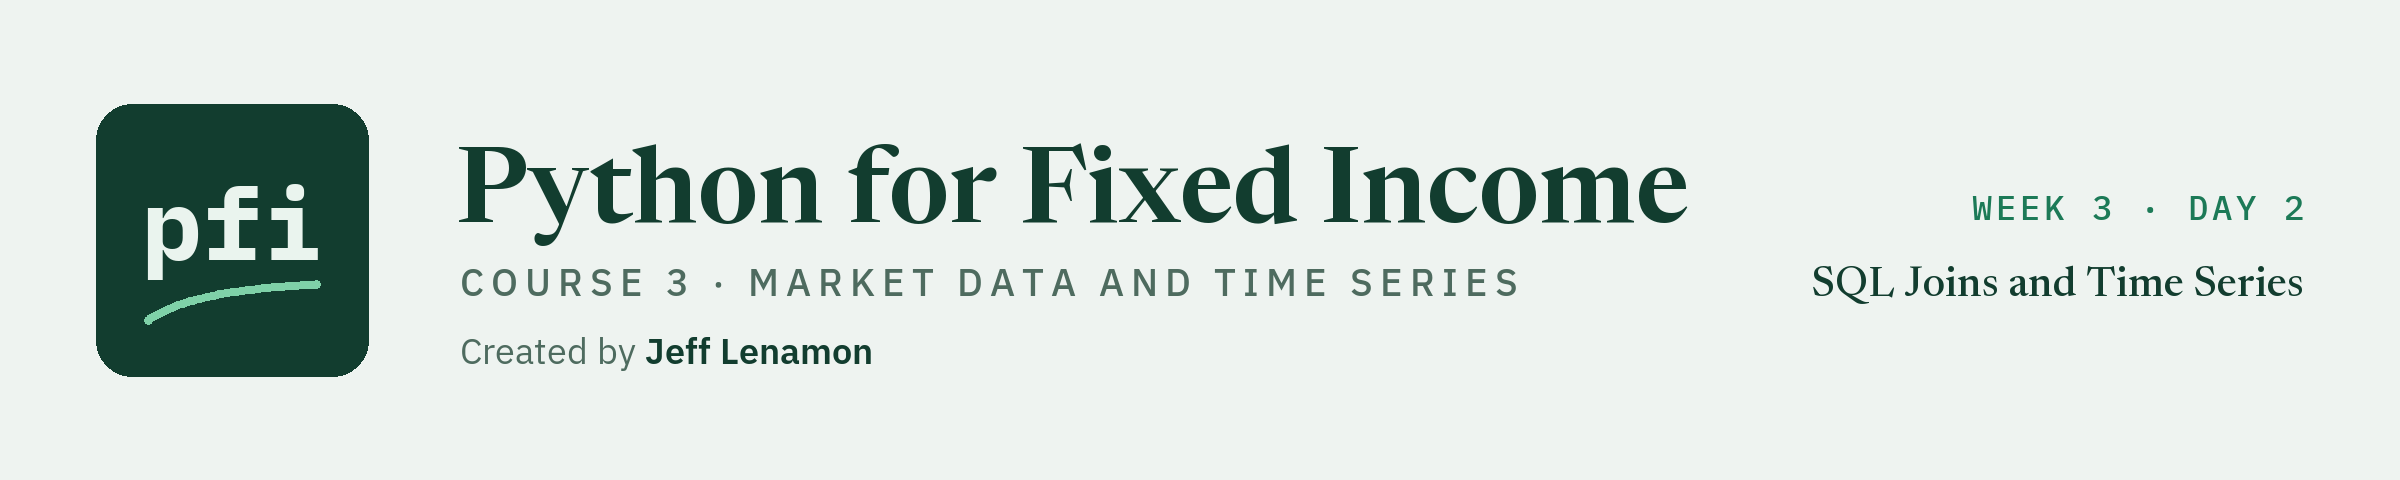

# SQL Joins and Time Series

Week 3, Day 2. Yesterday asked one table at a time. Today the tables meet: joins across the book, the issuers, the ratings, and the September trade blotter; the join that quietly duplicates rows and the count that catches it; and time series in SQL, with dates as text and window functions. Every query sits beside its pandas equivalent, and an assert compares them.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day2/12_sql_joins_and_time_series.ipynb)

Day 11 put the course's tables into one SQLite file and asked them questions one table at a time: `SELECT`, `WHERE`, `GROUP BY`, and the `?` parameter. Most real questions need two tables or more. Which sector was each September trade in? How much was traded in investment grade bonds? Which benchmark bonds does the book not hold? Each answer needs a **join**: rows of one table matched to rows of another on a key.

A join is also where SQL goes wrong without telling you. Match on a key that repeats, and the result has more rows than you started with, every sum is too large, and nothing raises an error. So today's habit is a count before and a count after every join.

Today you will:

1. Join holdings to issuers and ratings, and trades through holdings to ratings, in SQL and in pandas.
2. Use `LEFT JOIN` to find the benchmark bonds the book does not hold.
3. Walk into the duplicate trap on purpose, count it, and see `validate="many_to_one"` stop it in pandas.
4. Ask time series questions in SQL: dates as ISO text, `BETWEEN`, and months with `substr`.
5. Use two window functions, `LAG` and `ROW_NUMBER`, and prove them against `change_bp` and `last_per_period`.
6. Add two tests that tie it together.

Every result describes the synthetic book and the synthetic blotter. No trade, trader, or counterparty is judged, and no bond is called better or worse than another.

**No key today.** Every table is in the course repo, so nothing in this notebook goes to the network.

Q. Set up today's work folder and copy today's data files into it.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course03_market_data/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

9 packages checked, all present


In [2]:
# today's setup: modules, the course data, a fresh work folder, and the constants the live cells use
import importlib
import os
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

import pandas as pd

# the course's chart style, set once here so every chart in the notebook looks the same
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),          # width and height of a chart, in inches
    "figure.dpi": 110,                 # sharpness on screen
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    # the course greens, then a grey, for the first four lines or bars of a chart
    "axes.prop_cycle": plt.cycler(color=["#123d2f", "#1c7a57", "#7fd1a8", "#8c8c8c"]),
    "axes.grid": True,                 # light gridlines, as in an Excel chart
    "grid.color": "#dddddd",
    "axes.spines.top": False,          # no box line above or to the right of the plot
    "axes.spines.right": False,
})

# three packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("pytest", "pytest"), ("requests", "requests"), ("dotenv", "python-dotenv")]:
    try:
        importlib.import_module(module_name)
    except ImportError:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.") from None
import pytest
import requests

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()
data_folder = RAW_DATA if on_github else str(local_data) + os.sep

# 2. your own key file: in your my_bondmath folder, outside every repository. Its path is never printed.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"

# 3. the two constants of the live cells
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen unless you set this to True, on your own machine only
SHOW_LICENSED_VALUES = False

# 4. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course3_12_"))
os.chdir(work)

# 5. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv", "course3_fred_format_dgs10.json", "course3_fred_format_dgs2.json", "course3_excel_reference.csv", "holdings.csv", "issuers.csv", "ratings.csv", "benchmark.csv", "trade_blotter.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES) or 'none'}")
print(f"pytest {pytest.__version__}, requests {requests.__version__}")

Work folder: pfi_course3_12_lhiriy_4, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv, course3_fred_format_dgs10.json, course3_fred_format_dgs2.json, course3_excel_reference.csv, holdings.csv, issuers.csv, ratings.csv, benchmark.csv, trade_blotter.csv
pytest 9.1.1, requests 2.34.2


Q. Write `bondmath.py`, the reference copy of the module you finished in Course 2.

It is written into the work folder so that every notebook runs, in Colab too, whether or not you took Course 2. To use your own copy instead, run this line in a new cell after the next one:

```python
shutil.copy(Path.home() / "projects" / "my_bondmath" / "bondmath.py", work)
```

The saved outputs of this notebook always come from the reference copy.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `marketdata.py` and `test_marketdata.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)

Writing marketdata.py


In [5]:
%%writefile test_marketdata.py
"""Tests for marketdata.py.

Expected values come from Excel (course3_excel_reference.csv in this folder), from the course's data files, or
from small hand examples. No test touches the network or needs a real key: the only key is the course's fake one.
Run from this folder with:  python -m pytest
"""
import pytest

import marketdata as md

# the course's fake key: 32 lowercase letters, the shape FRED expects, obviously not a key
FAKE_KEY = "fakefakefakefakefakefakefakefake"
# the demo name; never FRED_API_KEY, because get_secret checks the environment first
DEMO_NAME = "DEMO_API_KEY"


def test_get_secret_reads_environment(monkeypatch, tmp_path):
    # monkeypatch sets the variable for this test only and removes it afterwards
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=tmp_path / ".env") == FAKE_KEY


def test_get_secret_reads_env_file(monkeypatch, tmp_path):
    # no variable in the environment, so the file is used
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}={FAKE_KEY}\n", encoding="utf-8")
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_environment_wins(monkeypatch, tmp_path):
    # both places hold a value: the environment comes first
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}=value-from-the-file\n", encoding="utf-8")
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_missing_raises_without_value(monkeypatch, tmp_path):
    # the file holds a different secret; the one asked for is nowhere
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"OTHER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    with pytest.raises(RuntimeError) as caught:
        md.get_secret(DEMO_NAME, env_file=env_file)
    message = str(caught.value)
    # the message names the secret and the places looked, and holds no value and no folder
    assert DEMO_NAME in message and "environment" in message and ".env" in message
    assert FAKE_KEY not in message
    assert str(tmp_path) not in message


import json  # the FRED-format samples, from day 2
import math  # NaN checks, from day 2
import traceback  # what a printed error would show, from day 2
from pathlib import Path  # this folder, from day 2

import pandas as pd  # dated series, from day 2
import requests  # its exception classes, from day 2

# the data files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_sample(series_id: str) -> dict:
    """A FRED-format sample from this folder: Treasury values in FRED's JSON layout, no network."""
    return json.loads((HERE / f"course3_fred_format_{series_id.lower()}.json").read_text(encoding="utf-8"))


class FakeResponse:
    """A stand-in for requests.Response: a status code, a JSON body, and a URL holding the key, no network."""

    def __init__(self, status_code: int, payload: dict):
        self.status_code = status_code
        self.payload = payload
        # a real response's URL holds the key; if fred_series ever printed it, the tests below would catch it
        self.url = f"{md.FRED_URL}?series_id=DGS10&api_key={FAKE_KEY}&file_type=json"

    def json(self) -> dict:
        return self.payload


def test_params_hold_series_and_json():
    params = md.fred_params("DGS10", FAKE_KEY, start="2015-01-01")
    assert params == {"series_id": "DGS10", "api_key": FAKE_KEY, "file_type": "json",
                      "observation_start": "2015-01-01"}
    # no end date asked for, so none is sent
    assert "observation_end" not in params


def test_parse_sample_counts_and_nan():
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    # 43 weekdays from 2026-08-03 to 2026-09-30, one of them FRED's "." on Labor Day
    assert len(series) == 43
    assert series.isna().sum() == 1
    assert math.isnan(series.loc["2026-09-07"])
    assert series.loc["2026-09-30"] == 5.29
    assert series.dtype == "float64"
    assert series.index.name == "date" and series.name == "DGS10"


def test_parse_raises_without_observations():
    with pytest.raises(ValueError):
        md.parse_fred_observations({"error_code": 400, "error_message": "Bad Request."}, "DGS10")


def test_fred_series_error_hides_key(monkeypatch):
    # an HTTP 400 answer with FRED's own message for a key that is not registered
    def fake_get_400(url, params, timeout):
        return FakeResponse(400, {"error_code": 400,
                                  "error_message": "Bad Request.  The value for variable api_key is not registered."})

    monkeypatch.setattr(requests, "get", fake_get_400)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert "HTTP 400" in str(caught.value) and "not registered" in str(caught.value)
    assert FAKE_KEY not in printed and "api_key=" not in printed

    # a connection error: requests puts the full URL, key included, in its message
    def fake_get_down(url, params, timeout):
        raise requests.ConnectionError(f"Max retries exceeded with url: /fred/series/observations?series_id=DGS10"
                                       f"&api_key={FAKE_KEY}&file_type=json")

    monkeypatch.setattr(requests, "get", fake_get_down)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert str(caught.value) == "Request for DGS10 failed: ConnectionError"
    # raised from None: no chained traceback carries the original message
    assert caught.value.__cause__ is None and caught.value.__suppress_context__
    assert FAKE_KEY not in printed and "api_key=" not in printed


def test_fred_series_empty_raises(monkeypatch):
    # FRED answers a range the series does not cover with HTTP 200 and no observations
    empty = read_sample("DGS10") | {"count": 0, "observations": []}
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, empty))
    with pytest.raises(RuntimeError):
        md.fred_series("DGS10", FAKE_KEY, start="2010-01-01", end="2010-12-31")
    # the same stand-in with the sample's observations parses as the sample does
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, read_sample("DGS10")))
    pd.testing.assert_series_equal(md.fred_series("DGS10", FAKE_KEY),
                                   md.parse_fred_observations(read_sample("DGS10"), "DGS10"))


def test_missing_weekdays_hand_index():
    # Friday 2026-09-04 to Wednesday 2026-09-09, with Monday (Labor Day) and Tuesday absent
    index = pd.DatetimeIndex(["2026-09-04", "2026-09-09"])
    missing = md.missing_weekdays(index)
    # the weekend is never counted; the two weekdays are
    assert list(missing) == [pd.Timestamp("2026-09-07"), pd.Timestamp("2026-09-08")]


def test_align_inner_keeps_common_dates():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    ten = pd.Series([5.20, 5.22, 5.25], index=dates)
    spread = pd.Series([98.0, 98.4], index=dates[[0, 2]])
    inner = md.align({"10 Yr": ten, "ig_spread_bp": spread})
    assert list(inner.index) == list(dates[[0, 2]])
    assert list(inner.columns) == ["10 Yr", "ig_spread_bp"]
    # an outer join keeps every date and leaves the gap empty, never filled
    outer = md.align({"10 Yr": ten, "ig_spread_bp": spread}, how="outer")
    assert len(outer) == 3 and math.isnan(outer.loc["2026-09-04", "ig_spread_bp"])


def test_align_rejects_unknown_how():
    ten = pd.Series([5.20], index=pd.to_datetime(["2026-09-03"]))
    with pytest.raises(ValueError):
        md.align({"10 Yr": ten}, how="left")


def test_stale_runs_finds_a_run():
    dates = pd.bdate_range("2026-09-01", periods=7)
    values = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2], index=dates)
    runs = md.stale_runs(values, min_length=3)
    # one run of four, from the second row to the fifth; the pair at the end is too short
    assert len(runs) == 1
    assert runs.loc[0, "start"] == dates[1] and runs.loc[0, "end"] == dates[4]
    assert runs.loc[0, "length"] == 4 and runs.loc[0, "value"] == 98.4


def read_treasury() -> pd.DataFrame:
    """The Treasury par yield file in this folder: one row per market date, yields in percent."""
    return pd.read_csv(HERE / "treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def test_month_end_label_is_observation_date():
    ten = read_treasury()["10 Yr"]
    month_end = md.last_per_period(ten, "ME")
    assert month_end.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert month_end.loc["2026-09-30"] == 5.29
    # May 2026 ends on Sunday 31, so its label is the last market day, Friday 29
    assert pd.Timestamp("2026-05-29") in month_end.index and pd.Timestamp("2026-05-31") not in month_end.index


def test_good_friday_week_takes_thursday():
    ten = read_treasury()["10 Yr"]
    weekly = md.last_per_period(ten, "W-FRI")
    # no row on Good Friday 2025-04-18, so the week is labelled by Thursday's row
    assert pd.Timestamp("2025-04-17") in weekly.index
    assert pd.Timestamp("2025-04-18") not in weekly.index
    assert weekly.loc["2025-04-17"] == ten.loc["2025-04-17"]


def test_value_as_of_holiday_returns_previous_day():
    ten = read_treasury()["10 Yr"]
    # Labor Day 2026-09-07 has no row: the as-of value is Friday 2026-09-04's
    as_of_date, value = md.value_as_of(ten, "2026-09-07")
    assert as_of_date == pd.Timestamp("2026-09-04")
    assert value == ten.loc["2026-09-04"]


def test_value_as_of_before_start_raises():
    ten = read_treasury()["10 Yr"]
    with pytest.raises(ValueError):
        md.value_as_of(ten, "2014-12-31")


def test_cache_round_trip_exact(tmp_path):
    # the FRED-format sample, "." row and all, through the cache and back
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    path = md.write_cache(series, tmp_path / "cache")
    assert path.name == "DGS10.csv"
    back = md.read_cache("DGS10", tmp_path / "cache")
    pd.testing.assert_series_equal(back, series, check_exact=True)
    # numbers with more digits than two also come back bit for bit
    awkward = (series.dropna() / 3).rename("THIRDS")
    md.write_cache(awkward, tmp_path / "cache")
    pd.testing.assert_series_equal(md.read_cache("THIRDS", tmp_path / "cache"), awkward, check_exact=True)


def test_read_cache_missing_raises(tmp_path):
    with pytest.raises(FileNotFoundError):
        md.read_cache("DGS10", tmp_path)


def test_licensed_series_not_cached(monkeypatch, tmp_path):
    # any attempt to reach the network fails the test
    def no_network(*args, **kwargs):
        raise AssertionError("cached_fred_series must not send a request for a licensed series")

    monkeypatch.setattr(requests, "get", no_network)
    for series_id in ("BAMLC0A0CM", "BAMLH0A0HYM2", "BAA10Y"):
        with pytest.raises(ValueError, match="licensed"):
            md.cached_fred_series(series_id, FAKE_KEY, tmp_path / "cache")
    # nothing was written
    assert not (tmp_path / "cache").exists()


def read_reference() -> pd.DataFrame:
    """The Excel reference rows in this folder: one per 2026 market date, every value computed by Excel."""
    return pd.read_csv(HERE / "course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                       float_precision="round_trip")


def test_change_bp_hand_series():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    yields = pd.Series([4.00, 4.10, 4.05], index=dates)
    changes = md.change_bp(yields)
    # 4.00 to 4.10 is 10 bp; the Tuesday after Labor Day is a change from Friday
    assert math.isnan(changes.iloc[0])
    assert changes.iloc[1] == pytest.approx(10.0, abs=1e-9)
    assert changes.loc["2026-09-08"] == pytest.approx(-5.0, abs=1e-9)
    assert md.change_bp(yields, periods=2).iloc[2] == pytest.approx(5.0, abs=1e-9)


def test_change_bp_spread_units():
    spreads = pd.Series([98.8, 101.3], index=pd.to_datetime(["2026-09-29", "2026-09-30"]))
    # a spread is already in bp, so nothing is multiplied
    assert md.change_bp(spreads, percent_units=False).iloc[1] == pytest.approx(2.5, abs=1e-9)


def test_return_pct_hand_series():
    prices = pd.Series([100.0, 101.0, 99.99], index=pd.to_datetime(["2026-09-28", "2026-09-29", "2026-09-30"]))
    returns = md.return_pct(prices)
    assert returns.iloc[1] == pytest.approx(1.0, abs=1e-12)
    assert returns.iloc[2] == pytest.approx(-1.0, abs=1e-12)


def test_change_since_uses_as_of_values():
    ten = read_treasury()["10 Yr"]
    # since Labor Day 2026-09-07 (no row) means since Friday 2026-09-04
    expected = (ten.loc["2026-09-30"] - ten.loc["2026-09-04"]) * 100
    assert md.change_since_bp(ten, "2026-09-30", "2026-09-07") == pytest.approx(expected, abs=1e-9)
    with pytest.raises(ValueError):
        md.change_since_bp(ten, "2026-09-07", "2026-09-30")


def test_change_bp_matches_excel_reference():
    reference = read_reference()
    ten = read_treasury()["10 Yr"]
    changes = md.change_bp(ten)
    for day, row in reference.iterrows():
        # Excel: =(D_t-D_t-1)*100, filled down
        assert changes.loc[day] == pytest.approx(row["chg_10y_bp"], abs=1e-9), day
        # the one-month as-of change: =(D_t-XLOOKUP(EDATE(A_t,-1),...,-1))*100
        month_back = day - pd.DateOffset(months=1)
        assert md.change_since_bp(ten, day, month_back) == pytest.approx(row["chg1m_10y_bp"], abs=1e-9), day


def assert_no_lookahead(func, series, cut_dates):
    """Check that func uses no future data: its output up to each cut date is the same whether the series
    stops at that date or runs on past it (exact equality, no tolerance)."""
    full = func(series)
    for cut in cut_dates:
        cut = pd.Timestamp(cut)
        # the same function on the series cut at that date
        cut_result = func(series.loc[:cut])
        pd.testing.assert_series_equal(full.loc[:cut], cut_result, check_exact=True)


# dates to cut the series at in the no-lookahead tests: a holiday week, a month end, and the file's last week
CUT_DATES = ["2025-04-17", "2026-06-30", "2026-09-30"]


def ten_year_changes() -> pd.Series:
    """Daily changes of the 10 Yr in bp, the first (NaN) dropped."""
    return md.change_bp(read_treasury()["10 Yr"]).dropna()


def test_vol_matches_excel_reference():
    reference = read_reference()
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    vol_annual = md.rolling_vol_bp(ten_year_changes(), window=21, annualise=True)
    for day, row in reference.iterrows():
        # Excel: =STDEV.S(F242:F262) filled down, and =G262*SQRT(252)
        assert vol.loc[day] == pytest.approx(row["vol21_10y_bp"], abs=1e-9), day
        assert vol_annual.loc[day] == pytest.approx(row["vol21_10y_annual_bp"], abs=1e-8), day


def test_vol_min_periods_nan():
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    # no partial windows: 20 NaN, then values
    assert vol.iloc[:20].isna().all()
    assert vol.iloc[20:].notna().all()


def test_vol_annualise_factor():
    changes = ten_year_changes()
    daily = md.rolling_vol_bp(changes, window=63)
    annual = md.rolling_vol_bp(changes, window=63, annualise=True)
    assert annual.iloc[-1] == pytest.approx(daily.iloc[-1] * math.sqrt(252), abs=1e-12)


def test_vol_no_lookahead():
    assert_no_lookahead(lambda s: md.rolling_vol_bp(s, window=63), ten_year_changes(), CUT_DATES)


def ten_year_and_2s10s() -> dict[str, pd.Series]:
    """The 10 Yr in percent and 2s10s in bp, (10 Yr - 2 Yr) x 100 as the Excel sheet computes it."""
    curve = read_treasury()
    return {"10y": curve["10 Yr"], "2s10s": (curve["10 Yr"] - curve["2 Yr"]) * 100}


def test_zscore_matches_excel_standardize():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        z = md.rolling_zscore(series, window=252)
        for day, row in reference.iterrows():
            assert z.loc[day] == pytest.approx(row[f"zscore252_{name}"], abs=1e-9), (name, day)


def test_zscore_nan_when_flat():
    dates = pd.bdate_range("2026-09-01", periods=6)
    stale = pd.Series([5.0, 5.0, 5.0, 5.0, 5.1, 5.0], index=dates)
    z = md.rolling_zscore(stale, window=3)
    # windows ending on the third and fourth rows are flat: no z-score
    assert z.iloc[:4].isna().all()
    assert z.iloc[4:].notna().all()


def test_percentile_matches_excel_countif():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        rank = md.rolling_percentile_rank(series, window=252)
        for day, row in reference.iterrows():
            # Excel: =COUNTIF(window,"<="&x)/COUNT(window)*100, a ratio of whole numbers
            assert rank.loc[day] == pytest.approx(row[f"pctrank252_{name}"], abs=1e-12), (name, day)


def test_percentile_ties_count_as_at_or_below():
    dates = pd.bdate_range("2026-09-01", periods=4)
    values = pd.Series([7.0, 9.0, 7.0, 7.0], index=dates)
    rank = md.rolling_percentile_rank(values, window=4)
    # three of the four values are at or below 7: 75 percent
    assert rank.iloc[-1] == pytest.approx(75.0, abs=1e-12)
    # two slopes of 32 bp with binary noise of opposite sign are still a tie: all three at or below
    noisy = pd.Series([(4.12 - 3.80) * 100, 31.0, (4.13 - 3.81) * 100], index=dates[:3])
    assert noisy.iloc[0] > 32 > noisy.iloc[2]
    assert md.rolling_percentile_rank(noisy, window=3).iloc[-1] == pytest.approx(100.0, abs=1e-12)


def test_zscore_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_zscore(s, window=252), series, CUT_DATES)


def test_percentile_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_percentile_rank(s, window=252), series, CUT_DATES)


def test_slope_sign():
    curve = pd.DataFrame({"2 Yr": [4.88, 5.10], "10 Yr": [5.29, 5.00]}, index=pd.to_datetime(["2026-09-30", "2026-10-01"]))
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # positive when the longer yield is higher, negative when it is lower
    assert slope.iloc[0] == pytest.approx(41.0, abs=1e-9)
    assert slope.iloc[1] == pytest.approx(-10.0, abs=1e-9)


def test_butterfly_hand_value():
    curve = pd.DataFrame({"2 Yr": [4.88], "5 Yr": [5.09], "10 Yr": [5.29]}, index=pd.to_datetime(["2026-09-30"]))
    # (2 x 5.09 - 4.88 - 5.29) x 100 = 1 bp
    assert md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr").iloc[0] == pytest.approx(1.0, abs=1e-9)


def test_butterfly_matches_excel_reference():
    reference = read_reference()
    curve = read_treasury().loc[reference.index]
    fly = md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # Excel: =(2*C_t-B_t-D_t)*100 and =(D_t-B_t)*100
    assert ((fly - reference["fly_2s5s10s_bp"]).abs() <= 1e-9).all()
    assert ((slope - reference["slope_2s10s_bp"]).abs() <= 1e-9).all()


def test_fly_weights_neutral():
    # DV01s per 100 of face per bp of par bonds at about 2, 5, and 10 years
    dv01_short, dv01_belly, dv01_long = 0.0186, 0.0436, 0.0778
    w_short, w_belly, w_long = md.fly_weights(dv01_short, dv01_belly, dv01_long)
    assert w_belly == 1.0
    # belly on one side, both wings on the other: the DV01s net to zero, half on each wing
    assert w_belly * dv01_belly - w_short * dv01_short - w_long * dv01_long == pytest.approx(0.0, abs=1e-15)
    assert w_short * dv01_short == pytest.approx(w_long * dv01_long, abs=1e-15)


def test_fly_weights_reject_nonpositive():
    with pytest.raises(ValueError):
        md.fly_weights(0.0186, 0.0, 0.0778)
    with pytest.raises(ValueError):
        md.fly_weights(-0.0186, 0.0436, 0.0778)


def ten_year_frame() -> tuple[pd.DataFrame, dict[str, str]]:
    """The 10 Yr in percent and 2s10s in bp side by side, with their units."""
    curve = read_treasury()
    data = pd.DataFrame({"10 Yr": curve["10 Yr"], "2s10s": md.slope_bp(curve, "2 Yr", "10 Yr")})
    return data, {"10 Yr": "pct", "2s10s": "bp"}


def test_summary_table_known_date():
    data, units = ten_year_frame()
    reference = read_reference().loc["2026-10-02"]
    table = md.summary_table(data, "2026-10-02", units)
    ten, slope = table.loc["10 Yr"], table.loc["2s10s"]
    assert ten["unit"] == "pct" and slope["unit"] == "bp"
    assert ten["level"] == 5.28
    assert ten["chg_1d_bp"] == pytest.approx(reference["chg_10y_bp"], abs=1e-9)
    assert ten["chg_1m_bp"] == pytest.approx(reference["chg1m_10y_bp"], abs=1e-9)
    # one week back from Friday 2026-10-02 is Friday 2026-09-25
    expected_week = (data.loc["2026-10-02", "10 Yr"] - data.loc["2026-09-25", "10 Yr"]) * 100
    assert ten["chg_1w_bp"] == pytest.approx(expected_week, abs=1e-9)
    assert ten["zscore"] == pytest.approx(reference["zscore252_10y"], abs=1e-9)
    assert ten["pct_rank"] == pytest.approx(reference["pctrank252_10y"], abs=1e-12)
    assert slope["level"] == pytest.approx(reference["slope_2s10s_bp"], abs=1e-9)
    assert slope["zscore"] == pytest.approx(reference["zscore252_2s10s"], abs=1e-9)
    assert slope["pct_rank"] == pytest.approx(reference["pctrank252_2s10s"], abs=1e-12)


def test_summary_table_no_lookahead():
    data, units = ten_year_frame()
    for cut in CUT_DATES:
        # the table from the whole file equals the table from the file cut at the as-of date
        full = md.summary_table(data, cut, units)
        cut_only = md.summary_table(data.loc[:cut], cut, units)
        pd.testing.assert_frame_equal(full, cut_only, check_exact=True)


def build_database(folder: Path) -> Path:
    """course3.db in `folder`, holding the holdings and ratings tables from this folder's CSV files."""
    db_path = folder / "course3.db"
    md.load_tables(db_path, {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    return db_path


def test_load_tables_counts(tmp_path):
    counts = md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    assert counts == {"holdings": 200, "ratings": 18}
    # loading again replaces the tables instead of adding rows
    assert md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv"}) == {"holdings": 200}
    with pytest.raises(ValueError):
        md.load_tables(tmp_path / "course3.db", {"holdings; DROP TABLE ratings": HERE / "holdings.csv"})


def test_run_query_params(tmp_path):
    db_path = build_database(tmp_path)
    holdings = pd.read_csv(HERE / "holdings.csv")
    result = md.run_query(db_path, "SELECT COUNT(*) AS bonds FROM holdings WHERE sector = ?", ("Energy",))
    assert result.loc[0, "bonds"] == (holdings["sector"] == "Energy").sum()
    # a value with a quote in it is just a value when it goes in as a parameter
    quoted = md.run_query(db_path, "SELECT * FROM holdings WHERE ticker = ?", ("O'BRN",))
    assert len(quoted) == 0
    with pytest.raises(FileNotFoundError):
        md.run_query(tmp_path / "missing.db", "SELECT 1")


def test_assert_same_rows_ignores_order(tmp_path):
    db_path = build_database(tmp_path)
    sql_result = md.run_query(db_path, "SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value "
                                       "FROM holdings GROUP BY sector ORDER BY market_value DESC")
    holdings = pd.read_csv(HERE / "holdings.csv")
    pandas_result = (holdings.groupby("sector", as_index=False)
                     .agg(market_value=("market_value", "sum"), bonds=("cusip", "count")))
    # different row order and column order, the same rows
    md.assert_same_rows(sql_result, pandas_result, sort_by=["sector"])


def test_assert_same_rows_catches_difference():
    left = pd.DataFrame({"sector": ["Energy", "Utilities"], "bonds": [20, 15]})
    right = pd.DataFrame({"sector": ["Utilities", "Energy"], "bonds": [15, 21]})
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, right, sort_by=["sector"])
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, left.rename(columns={"bonds": "count"}), sort_by=["sector"])

Writing test_marketdata.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata as md
# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(bondmath)
importlib.reload(md)
# the functions defined in each module itself, not the ones it imports
def own_functions(module):
    return [name for name, obj in vars(module).items() if callable(obj) and getattr(obj, "__module__", "") == module.__name__]

print(f"bondmath (the Course 2 reference): {len(own_functions(bondmath))} functions")
print(f"marketdata functions: {own_functions(md)}")

bondmath (the Course 2 reference): 25 functions
marketdata functions: ['get_secret', 'fred_params', 'parse_fred_observations', 'fred_series', '_check_index', 'missing_weekdays', 'align', 'stale_runs', '_check_series', 'last_per_period', 'value_as_of', 'write_cache', 'read_cache', 'cached_fred_series', 'change_bp', 'return_pct', 'change_since_bp', 'rolling_vol_bp', 'rolling_zscore', 'rolling_percentile_rank', 'slope_bp', 'butterfly_bp', 'fly_weights', 'summary_table', 'load_tables', 'run_query', 'assert_same_rows']


* `marketdata.py` is written as it stood at the end of day 11, with `load_tables`, `run_query`, and `assert_same_rows`. Today adds no function: it uses those three, and adds two tests.
* The data files include every file the test file reads, because pytest runs all 46 of yesterday's tests as well as today's.

## Today's Database

As on day 11, the database is `course3.db` in the work folder, deleted and rebuilt at the start of the notebook, and never in the day folder. Seven tables go in. Five come straight from CSV files. The Treasury file goes in **long form**, one row per date and tenor, because a table with one yield column is far easier to query than one with a column per tenor.

Q. Read the Treasury file and turn it into long form, with dates as ISO text.

In [7]:
# the curve in wide form: one row per market date, one column per tenor, yields in percent
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def tenor_years(label):
    """Years to maturity of a tenor label: '3 Mo' and '1.5 Month' count months, '10 Yr' counts years."""
    number, unit = label.split(" ")
    return float(number) / 12 if unit in ("Mo", "Month") else float(number)


# melt turns the tenor columns into rows; dropna drops a tenor with no value on that date
treasury_long = curve.reset_index().melt(id_vars="date", var_name="tenor", value_name="yield_pct").dropna()
treasury_long["years"] = treasury_long["tenor"].map(tenor_years)
# dates as ISO text, YYYY-MM-DD: SQLite has no date type, and ISO text sorts in date order
treasury_long["date"] = treasury_long["date"].dt.strftime("%Y-%m-%d")
treasury_long = treasury_long[["date", "tenor", "years", "yield_pct"]]
treasury_long.to_csv("treasury_long.csv", index=False)
print(f"{len(curve):,} dates by {curve.shape[1]} tenors: {len(treasury_long):,} rows in long form")
treasury_long.head(3)

2,940 dates by 14 tenors: 35,728 rows in long form


,date,tenor,years,yield_pct
0,2015-01-02,1 Mo,0.083333,0.02
1,2015-01-05,1 Mo,0.083333,0.02
2,2015-01-06,1 Mo,0.083333,0.02


* 2,940 dates times 14 tenors would be 41,160 cells, but some tenors start late, so 35,728 rows hold a yield. A missing value is dropped, never stored as a zero.

Q. Delete any old database and load the seven tables with `load_tables`.

In [8]:
DB_PATH = work / "course3.db"
# start from nothing, so no table survives from an earlier run of this notebook
DB_PATH.unlink(missing_ok=True)

tables = {"holdings": work / "holdings.csv", "issuers": work / "issuers.csv", "ratings": work / "ratings.csv",
          "benchmark": work / "benchmark.csv", "trades": work / "trade_blotter.csv",
          "treasury": work / "treasury_long.csv", "spreads": work / "course3_synthetic_spreads.csv"}
# load_tables writes each CSV to a table and checks each count against the CSV
counts = md.load_tables(DB_PATH, tables)
for name, count in counts.items():
    print(f"{name:10} {count:6,} rows")

holdings      200 rows
issuers       150 rows
ratings        18 rows
benchmark     821 rows
trades        374 rows
treasury   35,728 rows
spreads     2,940 rows


* `spreads` is the course's **synthetic** credit spread file, invented for the course: it is not ICE, Moody's, or any index.

Q. Read the same files into pandas, for the pandas side of every comparison.

In [9]:
holdings = pd.read_csv("holdings.csv")
issuers = pd.read_csv("issuers.csv")
ratings = pd.read_csv("ratings.csv")
benchmark = pd.read_csv("benchmark.csv")
trades = pd.read_csv("trade_blotter.csv")
spreads = pd.read_csv("course3_synthetic_spreads.csv")
print(f"trades: {len(trades)} rows, {trades['trade_date'].min()} to {trades['trade_date'].max()}, "
      f"principal {trades['principal'].sum():,.2f} dollars")

trades: 374 rows, 2026-09-01 to 2026-09-30, principal 117,473,749.35 dollars


* 374 trades over 21 trading days of September 2026, with 117,473,749.35 dollars of principal. That total is the **control figure** for every join today that starts from the trades: a join that keeps one row per trade keeps this total to the cent.

## 12.1 JOIN: Holdings to Issuers and Ratings

A join matches each row of one table to rows of another where a key is equal. The commonest kind on a desk is **many to one**: many holdings share one issuer, and many holdings share one rating, so each holding finds exactly one issuer row and one rating row. Many to one is safe only when the key is **unique on the "one" side**. So check that first.

Q. Before joining: how many rows and how many distinct keys does each table have?

In [10]:
# COUNT(DISTINCT column) counts the different values; a key is unique when it equals COUNT(*)
key_counts = md.run_query(DB_PATH, """
    SELECT 'holdings' AS tbl, COUNT(*) AS n_rows, COUNT(DISTINCT cusip) AS distinct_cusip,
           COUNT(DISTINCT ticker) AS distinct_ticker FROM holdings
    UNION ALL
    SELECT 'issuers', COUNT(*), NULL, COUNT(DISTINCT ticker) FROM issuers
""")
key_counts

,tbl,n_rows,distinct_cusip,distinct_ticker
0,holdings,200,200.0,115
1,issuers,150,NaN,150


* Holdings: 200 rows, 200 distinct cusips, 115 distinct tickers. A cusip names one bond; a ticker names an issuer, and many issuers have more than one bond in the book.
* Issuers: 150 rows and 150 distinct tickers, so `ticker` is unique there. Joining holdings to issuers on ticker is many to one, and it is safe.
* `UNION ALL` stacks the rows of two queries with the same number of columns. The second row has no cusip column to count, so it says `NULL`.

Q. Join each holding to its issuer and its rating, in SQL.

In [11]:
# JOIN ... ON matches rows where the keys are equal; AS gives each table a short name for the columns
book_sql = md.run_query(DB_PATH, """
SELECT h.cusip, h.ticker, i.issuer, i.country, h.rating, r.bucket, r.grade, h.market_value
FROM holdings AS h
JOIN issuers AS i ON h.ticker = i.ticker
JOIN ratings AS r ON h.rating = r.rating
""")
print(f"{len(book_sql)} rows")
book_sql.head(3)

200 rows


,cusip,ticker,issuer,country,rating,bucket,grade,market_value
0,99080CAE8,BEZE,Bezane Finance,US,BBB-,BBB,Investment Grade,5435500.0
1,99049XAE2,BEZH,Bezamyth Machinery,US,B,B,High Yield,253087.5
2,99039NAC0,BEZL,Bezoquil Freight,US,BB,BB,High Yield,1505940.0


* 200 rows in, 200 rows out: every holding found one issuer and one rating.
* `holdings AS h` gives the table a short name, so `h.ticker` means the ticker column of holdings and `i.ticker` the one of issuers. `JOIN issuers AS i ON h.ticker = i.ticker` reads: for each holding, find the issuer row with the same ticker.
* `JOIN` on its own is an **inner join**: a holding whose ticker had no issuer row would be dropped, with no message. The count is what tells you nothing was.

Q. The same join in pandas, with `validate=` to check the keys, then compare the two.

In [12]:
# validate="many_to_one" stops the merge if the key repeats on the right
book_pandas = (holdings[["cusip", "ticker", "rating", "market_value"]]
               .merge(issuers[["ticker", "issuer", "country"]], on="ticker", how="inner", validate="many_to_one")
               .merge(ratings[["rating", "bucket", "grade"]], on="rating", how="inner", validate="many_to_one"))

# same columns, same rows, in any order: cusip is unique, so it is the sort key
md.assert_same_rows(book_sql, book_pandas, sort_by=["cusip"])
print(f"SQL and pandas agree on all {len(book_pandas)} rows and {book_pandas.shape[1]} columns")

SQL and pandas agree on all 200 rows and 8 columns


* The SQL `JOIN ... ON` is pandas' `merge(..., on=, how="inner")`. The SQL has no `validate=`; its check is the count.
* `merge` joins two DataFrames on a key column. The brackets around the whole chain let one expression run over several lines, one `.merge` on each. `holdings[["cusip", ...]]` picks the columns to bring along.
* `reset_index`, `melt`, `.map`, and `.dt.strftime` in the long-form cell did four small jobs: `reset_index` turned the date index back into a column, `melt` turned the tenor columns into rows, `.map(tenor_years)` ran a function on every label, and `.dt.strftime("%Y-%m-%d")` wrote each date as ISO text.

Q. Now three tables in a chain: trades to holdings on cusip, then holdings to ratings. How many trades, and how much principal, in each grade?

In [13]:
by_grade_sql = md.run_query(DB_PATH, """
SELECT r.grade, COUNT(*) AS trades, SUM(t.principal) AS principal
FROM trades AS t
JOIN holdings AS h ON t.cusip = h.cusip
JOIN ratings AS r ON h.rating = r.rating
GROUP BY r.grade
ORDER BY r.grade
""")

# a styled table: .format sets the digits (Excel: Format Cells), .bar draws a bar in each cell (Excel: Data Bars)
(by_grade_sql.style
    .hide(axis="index")
    .format({"trades": "{:,}", "principal": "{:,.2f}"})
    .bar(subset=["principal"], color="#7fd1a8")
    .set_caption("Trades and principal (dollars) by grade, from two joins"))

grade,trades,principal
High Yield,140,"24,176,618.65"
Investment Grade,234,"93,297,130.70"


In [14]:
by_grade_pandas = (trades.merge(holdings[["cusip", "rating"]], on="cusip", validate="many_to_one")
                   .merge(ratings[["rating", "grade"]], on="rating", validate="many_to_one")
                   .groupby("grade", as_index=False)
                   .agg(trades=("trade_id", "count"), principal=("principal", "sum")))
md.assert_same_rows(by_grade_sql, by_grade_pandas, sort_by=["grade"])

# the control figures: every trade counted once, and the blotter's principal to the cent
assert by_grade_sql["trades"].sum() == len(trades)
assert round(by_grade_sql["principal"].sum(), 2) == round(trades["principal"].sum(), 2)
print(f"{by_grade_sql['trades'].sum()} trades and {by_grade_sql['principal'].sum():,.2f} dollars: the blotter's totals")

374 trades and 117,473,749.35 dollars: the blotter's totals


* 234 investment grade trades with 93,297,130.70 dollars of principal, and 140 high yield trades with 24,176,618.65 dollars.
* The two grades add back to the blotter: 374 trades and 117,473,749.35 dollars. Two joins, and the control figures still hold, so neither join added or lost a row.
* The table above is a **styled table**: `.style` dresses a DataFrame the way you dress a range in Excel. `.format` is Format Cells, with the thousands commas and the decimals. `.bar` draws a bar inside each cell in proportion to its value, which is Excel's Data Bars under Conditional Formatting. `.hide(axis="index")` drops the row numbers, and `.set_caption` is the title. The numbers underneath do not change.

Q. Draw the two grades side by side, trade count and principal.

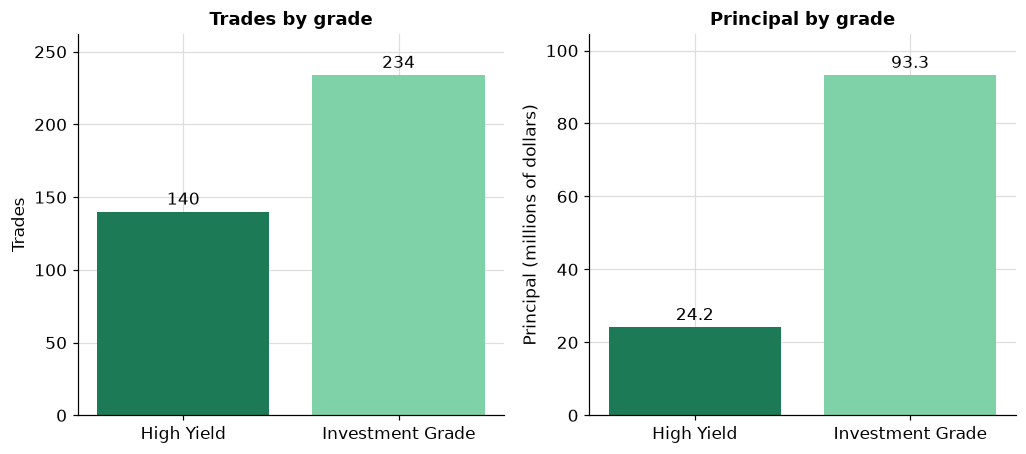

In [15]:
# the result of the two joins, drawn: one panel for the count and one for the dollars
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5))
left.bar(by_grade_sql["grade"], by_grade_sql["trades"], color=["#1c7a57", "#7fd1a8"])
left.bar_label(left.containers[0], padding=2)
left.set_ylabel("Trades")
left.set_title("Trades by grade")
right.bar(by_grade_sql["grade"], by_grade_sql["principal"] / 1e6, color=["#1c7a57", "#7fd1a8"])
right.bar_label(right.containers[0], fmt="%.1f", padding=2)
right.set_ylabel("Principal (millions of dollars)")
right.set_title("Principal by grade")
for ax in (left, right):
    ax.set_axisbelow(True)
    ax.margins(y=0.12)
plt.show()

* Left: how many trades. Right: how many dollars. The two joins carried every trade to a grade, so the bars add back to the blotter's totals.

## 12.2 LEFT JOIN: What Does Not Match

An inner join keeps only rows that match. A **LEFT JOIN** keeps every row of the left table; where nothing matches, the right table's columns come back as `NULL`, which pandas reads as `NaN` or `None`. Keeping the unmatched rows is how you find them.

The benchmark has 821 bonds. Which of them does the book not hold?

Q. Benchmark bonds with no matching cusip in holdings, in SQL.

In [16]:
# keep every benchmark row; h.cusip is NULL where the book has no bond with that cusip
not_held_sql = md.run_query(DB_PATH, """
SELECT b.cusip, b.ticker, b.sector, b.weight_pct
FROM benchmark AS b
LEFT JOIN holdings AS h ON b.cusip = h.cusip
WHERE h.cusip IS NULL
""")
print(f"{len(not_held_sql)} benchmark bonds are not in the book")
not_held_sql.head(3)

621 benchmark bonds are not in the book


,cusip,ticker,sector,weight_pct
0,99001BAB2,QVNE,Energy,0.1551
1,99001BAC0,QVNE,Energy,0.0245
2,99001BAD8,QVNE,Energy,0.2024


* `WHERE h.cusip IS NULL` keeps the rows that found no match. In SQL nothing equals `NULL`, not even `NULL`, so the test is `IS NULL`, never `= NULL`.

Q. The same in pandas: a left merge with `indicator=True`, which labels each row by where it was found.

In [17]:
# indicator=True adds _merge: "both" where a match was found, "left_only" where none was
flagged = benchmark.merge(holdings[["cusip"]], on="cusip", how="left", indicator=True, validate="one_to_one")
not_held_pandas = flagged.loc[flagged["_merge"] == "left_only", ["cusip", "ticker", "sector", "weight_pct"]]

md.assert_same_rows(not_held_sql, not_held_pandas, sort_by=["cusip"])
print(flagged["_merge"].value_counts().to_string())

_merge
left_only     621
both          200
right_only      0


* 200 benchmark bonds are in the book and 621 are not; 200 plus 621 is 821, every benchmark row once. `validate="one_to_one"` held: cusip is unique on both sides.

Q. Draw what `JOIN` and `LEFT JOIN` keep. Take eight benchmark bonds, four the book holds and four it does not, and run both real queries.

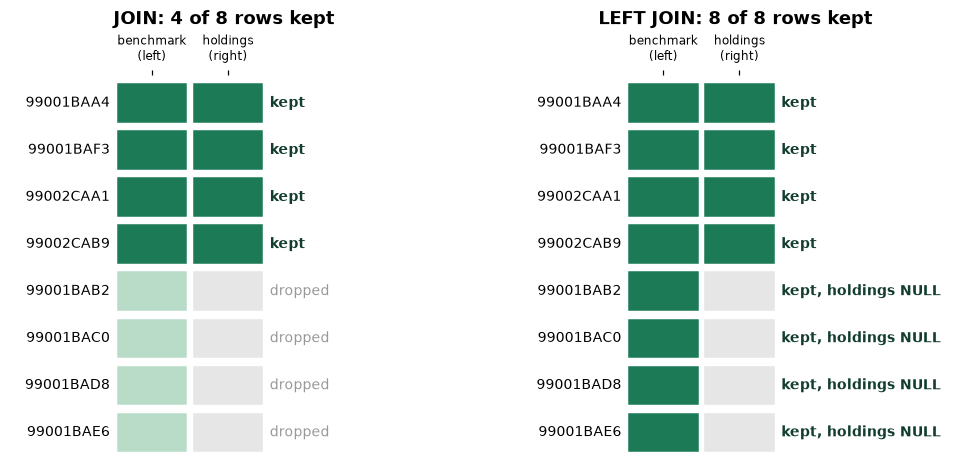

In [18]:
from matplotlib.patches import Rectangle

# eight benchmark bonds: the first four the book holds and the first four it does not
sample = list(flagged.loc[flagged["_merge"] == "both", "cusip"].head(4)) + list(not_held_sql["cusip"].head(4))
held_cusips = set(holdings["cusip"])

# the cusips each real query returns, on the full tables
inner_sql = "SELECT b.cusip FROM benchmark AS b JOIN holdings AS h ON b.cusip = h.cusip"
left_sql = "SELECT b.cusip FROM benchmark AS b LEFT JOIN holdings AS h ON b.cusip = h.cusip"
kept_by = {"JOIN": set(md.run_query(DB_PATH, inner_sql)["cusip"]),
           "LEFT JOIN": set(md.run_query(DB_PATH, left_sql)["cusip"])}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, kept_by):
    for row, cusip in enumerate(sample):
        y = len(sample) - row
        kept = cusip in kept_by[name]
        matched = cusip in held_cusips
        # left box: the benchmark row. right box: the holdings row it finds, grey where it finds none
        ax.add_patch(Rectangle((0, y), 0.9, 0.8, color="#1c7a57" if kept else "#b9dcc9"))
        ax.add_patch(Rectangle((1, y), 0.9, 0.8, color=("#1c7a57" if kept else "#b9dcc9") if matched else "#e6e6e6"))
        ax.text(-0.1, y + 0.4, cusip, ha="right", va="center", fontsize=9)
        if not kept:
            label = "dropped"
        elif matched:
            label = "kept"
        else:
            label = "kept, holdings NULL"
        ax.text(2.0, y + 0.4, label, va="center", fontsize=9, fontweight="bold" if kept else "normal",
                color="#123d2f" if kept else "#999999")
    ax.set_title(f"{name}: {sum(c in kept_by[name] for c in sample)} of {len(sample)} rows kept")
    ax.set_xlim(-1.4, 4.2)
    ax.set_ylim(0.9, len(sample) + 1)
    ax.xaxis.tick_top()
    ax.set_xticks([0.45, 1.45], ["benchmark\n(left)", "holdings\n(right)"], fontsize=8)
    ax.set_yticks([])
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
plt.show()

* Dark green: the row is kept. Pale green: it is in the table, but the join dropped it. Grey: the table has no row with that key.
* The first four bonds are in both tables, so both joins keep them. The last four are only in the benchmark: `JOIN` drops them without a word, and `LEFT JOIN` keeps them with `NULL` where the holdings columns would be.
* For adding details to a list you must not lose, use `LEFT JOIN`. This is the SQL twin of Course 1's four merges drawn side by side.

Q. Count the rows each query returns on the whole benchmark.

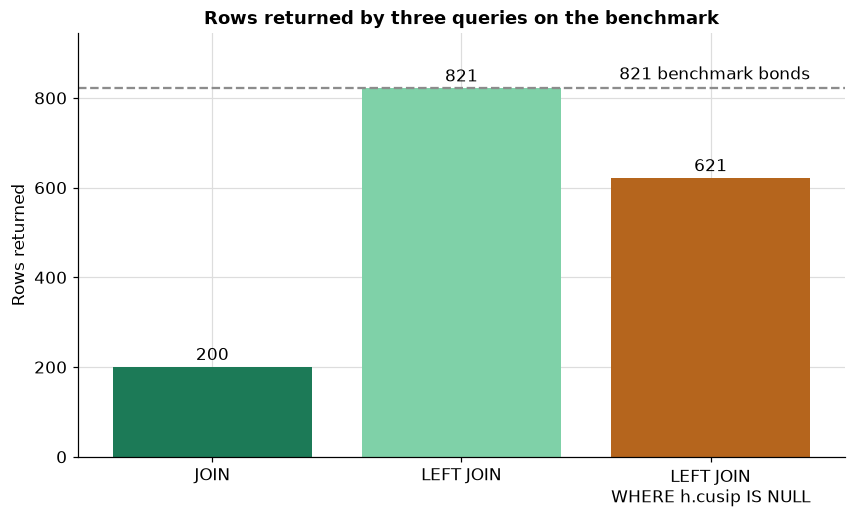

In [19]:
# COUNT(*) of each query, from the database; the benchmark has one row for each bond
n_inner = md.run_query(DB_PATH, "SELECT COUNT(*) AS n FROM benchmark AS b JOIN holdings AS h ON b.cusip = h.cusip").loc[0, "n"]
n_left = md.run_query(DB_PATH, "SELECT COUNT(*) AS n FROM benchmark AS b LEFT JOIN holdings AS h ON b.cusip = h.cusip").loc[0, "n"]
n_unmatched = len(not_held_sql)

fig, ax = plt.subplots()
bars = ax.bar(["JOIN", "LEFT JOIN", "LEFT JOIN\nWHERE h.cusip IS NULL"], [n_inner, n_left, n_unmatched],
              color=["#1c7a57", "#7fd1a8", "#b5651d"])
ax.bar_label(bars, padding=2)
# the dashed line is the benchmark itself: what LEFT JOIN keeps
ax.axhline(len(benchmark), linestyle="--", color="#8c8c8c")
ax.annotate(f"{len(benchmark)} benchmark bonds", (2.4, len(benchmark)), textcoords="offset points", xytext=(0, 6), ha="right")
ax.set_axisbelow(True)
ax.set_ylim(0, len(benchmark) * 1.15)
ax.set_ylabel("Rows returned")
ax.set_title("Rows returned by three queries on the benchmark")
plt.show()

* `LEFT JOIN` reaches the dashed line: every benchmark row, once. `JOIN` keeps only the bonds the book holds, and the last bar is the ones it does not.

Q. How much benchmark weight sits in bonds the book holds, and how much in bonds it does not?

In [20]:
# CASE WHEN gives each row a label; GROUP BY then adds up each label
coverage_sql = md.run_query(DB_PATH, """
    SELECT CASE WHEN h.cusip IS NULL THEN 'not held' ELSE 'held' END AS in_book,
           COUNT(*) AS bonds, SUM(b.weight_pct) AS weight_pct
    FROM benchmark AS b
    LEFT JOIN holdings AS h ON b.cusip = h.cusip
    GROUP BY in_book
""")
coverage_pandas = (flagged.assign(in_book=flagged["_merge"].map({"both": "held", "left_only": "not held"}))
                   .groupby("in_book", as_index=False)
                   .agg(bonds=("cusip", "count"), weight_pct=("weight_pct", "sum")))
md.assert_same_rows(coverage_sql, coverage_pandas, sort_by=["in_book"])

# a styled table: highlight_max shades the larger weight (Excel: Conditional Formatting, Top/Bottom Rules)
(coverage_sql.style
    .hide(axis="index")
    .format({"bonds": "{:,}", "weight_pct": "{:.4f}"})
    .highlight_max(subset=["weight_pct"], color="#bfe8d2")
    .set_caption("Benchmark bonds and weight (percent) the book holds and does not hold"))

in_book,bonds,weight_pct
held,200,24.5577
not held,621,75.4426


* The 200 bonds the book holds carry 24.5577 percent of the benchmark's weight; the 621 it does not hold carry 75.4426 percent. That describes coverage; it says nothing about what the book should hold.
* The same left join, pointed the other way, finds issuers with no bond in the book: 35 of the 150 issuers.
* `CASE WHEN ... THEN ... ELSE ... END` gives each row a label, here `held` or `not held`, and `GROUP BY in_book` then adds up each label. It is Excel's `IF` written inside a query.

Q. Draw the two weights.

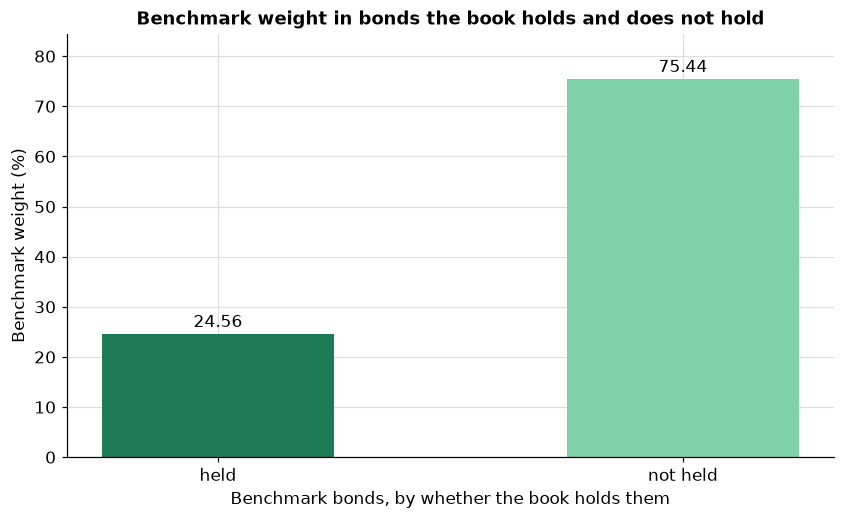

In [21]:
# the same two rows as the table: share of the benchmark's weight, held against not held
fig, ax = plt.subplots()
bars = ax.bar(coverage_sql["in_book"], coverage_sql["weight_pct"], color=["#1c7a57", "#7fd1a8"], width=0.5)
ax.bar_label(bars, fmt="%.2f", padding=2)
ax.set_axisbelow(True)
ax.margins(y=0.12)
ax.set_xlabel("Benchmark bonds, by whether the book holds them")
ax.set_ylabel("Benchmark weight (%)")
ax.set_title("Benchmark weight in bonds the book holds and does not hold")
plt.show()

* The two bars add to the benchmark's whole weight. The chart describes coverage of this synthetic benchmark, nothing more.

## 12.3 The Duplicate Trap

Here is the mistake this whole day is built around, made on purpose. You want each holding's benchmark weight beside it. Both tables have a `ticker` column, so you join on ticker.

**Predict.** Holdings has 200 rows. How many rows does the join below return: fewer than 200, exactly 200, or more?

Q. Count the rows before, join holdings to the benchmark on ticker, and count after.

In [22]:
rows_before = md.run_query(DB_PATH, "SELECT COUNT(*) AS n FROM holdings").loc[0, "n"]
trap = md.run_query(DB_PATH, """
    SELECT h.cusip, h.ticker, h.market_value, b.weight_pct
    FROM holdings AS h
    JOIN benchmark AS b ON h.ticker = b.ticker
""")
print(f"rows before: {rows_before}, rows after: {len(trap)}")
print(f"market value before: {holdings['market_value'].sum():,.2f} dollars, after: {trap['market_value'].sum():,.2f} dollars")

rows before: 200, rows after: 1213
market value before: 490,819,215.00 dollars, after: 2,993,789,415.00 dollars


* 200 rows became 1,213, and the book's 490,819,215.00 dollars of market value became 2,993,789,415.00. No error, no warning: SQL did exactly what it was asked.
* Each holding matched **every** benchmark bond of the same issuer. A holding of an issuer with 8 bonds in the benchmark now appears 8 times, and its market value is counted 8 times in any sum.

Q. Draw the damage: rows and market value before and after the join.

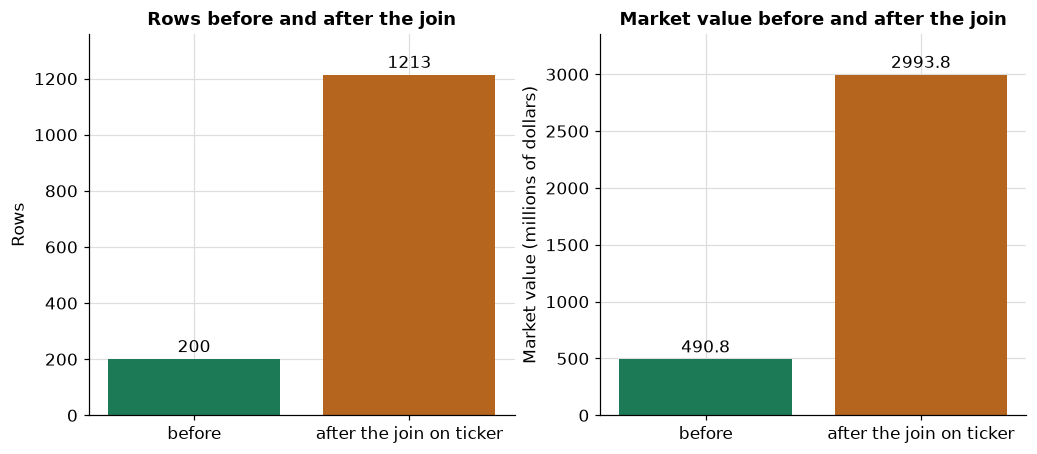

In [23]:
# left: row counts. right: the book's market value in millions of dollars
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, values, fmt, label, title in [
        (left, [rows_before, len(trap)], "%d", "Rows", "Rows before and after the join"),
        (right, [holdings["market_value"].sum() / 1e6, trap["market_value"].sum() / 1e6], "%.1f",
         "Market value (millions of dollars)", "Market value before and after the join")]:
    bars = ax.bar(["before", "after the join on ticker"], values, color=["#1c7a57", "#b5651d"])
    ax.bar_label(bars, fmt=fmt, padding=2)
    ax.set_axisbelow(True)
    ax.margins(y=0.12)
    ax.set_ylabel(label)
    ax.set_title(title)
plt.show()

* Left: the rows grew. Right: so did the dollars, though no bond was bought. The join counted each holding once for every benchmark bond of its issuer, which is why a total after a join must be compared with the total before.

Q. Which key repeats? Count the benchmark's tickers.

In [24]:
# HAVING keeps the groups whose count is above 1: the keys that repeat
repeats_sql = md.run_query(DB_PATH, """
SELECT ticker, COUNT(*) AS bonds
FROM benchmark
GROUP BY ticker
HAVING COUNT(*) > 1
ORDER BY bonds DESC, ticker
""")
repeats_pandas = (benchmark.groupby("ticker", as_index=False).agg(bonds=("cusip", "count"))
                  .query("bonds > 1"))
md.assert_same_rows(repeats_sql, repeats_pandas, sort_by=["ticker"])
print(f"{len(repeats_sql)} tickers have more than one bond in the benchmark, up to {repeats_sql['bonds'].max()}")
repeats_sql.head(3)

150 tickers have more than one bond in the benchmark, up to 8


,ticker,bonds
0,BRUH,8
1,CORA,8
2,CORH,8


* All 150 of the benchmark's tickers have more than one bond, up to 8. A ticker is not a key for the benchmark; a cusip is.
* `GROUP BY ticker HAVING COUNT(*) > 1` counts the rows of each ticker and keeps the tickers that appear more than once. In pandas, `.groupby(...).agg(...)` counts and `.query("bonds > 1")` keeps the groups that pass: the same two steps.

Q. Draw how many benchmark bonds each ticker has.

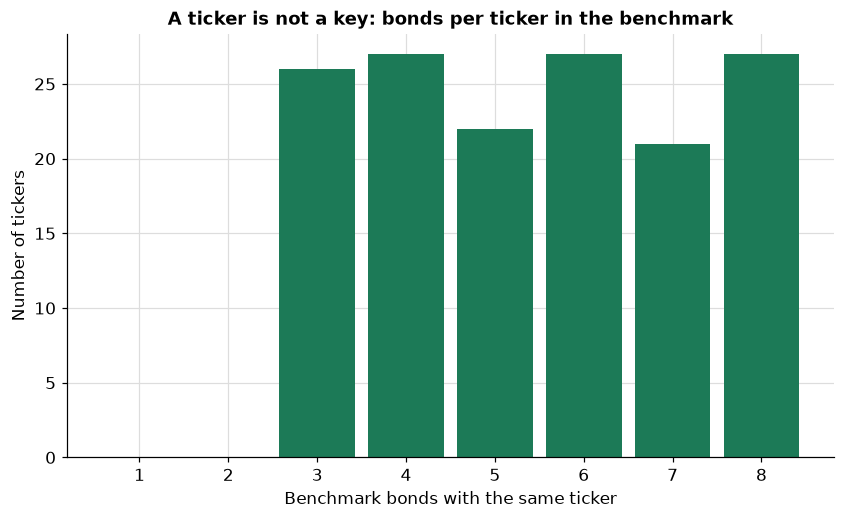

In [25]:
# value_counts gives one number for each ticker: how many benchmark rows carry it
per_ticker = benchmark["ticker"].value_counts()
fig, ax = plt.subplots()
ax.hist(per_ticker, bins=range(1, per_ticker.max() + 2), align="left", rwidth=0.85, color="#1c7a57")
ax.set_xticks(range(1, per_ticker.max() + 1))
ax.set_axisbelow(True)
ax.set_xlabel("Benchmark bonds with the same ticker")
ax.set_ylabel("Number of tickers")
ax.set_title("A ticker is not a key: bonds per ticker in the benchmark")
plt.show()

* A bar at 1 would be a ticker that names one bond. 150 of the 150 tickers sit at 2 or more, so a join on ticker repeats each holding once for every benchmark bond its issuer has: the number on the x axis.

Q. In pandas, `validate="many_to_one"` says what you expect before the merge runs. Does it stop this one?

In [26]:
try:
    holdings.merge(benchmark[["ticker", "weight_pct"]], on="ticker", validate="many_to_one")
except pd.errors.MergeError as error:
    # the first line of the message says why; the rest lists the repeated keys
    print(f"MergeError: {str(error).splitlines()[0]}")

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge


* pandas refuses the merge before building it: the right table's keys are not unique, so this cannot be many to one. SQL has no such switch; a count before and after is SQL's `validate=`.

Q. The fix: join on cusip, which names one bond. Count again, in both.

In [27]:
fixed_sql = md.run_query(DB_PATH, """
    SELECT h.cusip, h.ticker, h.market_value, b.weight_pct
    FROM holdings AS h
    JOIN benchmark AS b ON h.cusip = b.cusip
""")
fixed_pandas = (holdings[["cusip", "ticker", "market_value"]]
                .merge(benchmark[["cusip", "weight_pct"]], on="cusip", validate="many_to_one"))
md.assert_same_rows(fixed_sql, fixed_pandas, sort_by=["cusip"])

# the check that catches the trap: a lookup join keeps the left table's row count and its totals
assert len(fixed_sql) == rows_before
assert round(fixed_sql["market_value"].sum(), 2) == round(holdings["market_value"].sum(), 2)
print(f"rows before: {rows_before}, rows after: {len(fixed_sql)}, market value unchanged")

rows before: 200, rows after: 200, market value unchanged


* Same rows, same total. The rule for every lookup join: **count before, count after, compare a total**. In pandas, add `validate=` as well.

## 12.4 Time Series in SQL: Dates as Text

SQLite has no date type. The course stores dates as **ISO text**, `YYYY-MM-DD`, and that one choice makes dates work: ISO text sorts and compares in date order, character by character, because the year comes first, then the month, then the day, each with a fixed width.

Q. What type does SQLite say a date is, and does text order equal date order?

In [28]:
dates_check = md.run_query(DB_PATH, """
    SELECT typeof(date) AS stored_as,
           '2026-09-30' < '2026-10-02' AS iso_in_order,
           '09/30/2026' < '10/02/2025' AS us_text_in_order
    FROM treasury LIMIT 1
""")
dates_check

,stored_as,iso_in_order,us_text_in_order
0,text,1,1


* `text`, and the comparisons come back as 1 for true. The ISO pair is in the right order. The US-format pair says 30 September 2026 comes **before** 2 October 2025, because text compares the month first. Dates written as `MM/DD/YYYY` sort wrongly as text; that is why the course stores ISO text and nothing else.

Q. Every 10-year yield in September 2026, with `BETWEEN` and `?` parameters.

In [29]:
# BETWEEN includes both ends; the tenor and both dates go in as parameters
sept_sql = md.run_query(DB_PATH, """
SELECT date, yield_pct
FROM treasury
WHERE tenor = ? AND date BETWEEN ? AND ?
ORDER BY date
""", ("10 Yr", "2026-09-01", "2026-09-30"))

# pandas: a label slice of the dated index, which also includes both ends
sept = curve.loc["2026-09-01":"2026-09-30", "10 Yr"]
sept_pandas = pd.DataFrame({"date": sept.index.strftime("%Y-%m-%d"), "yield_pct": sept.to_numpy()})
md.assert_same_rows(sept_sql, sept_pandas, sort_by=["date"])
print(f"{len(sept_sql)} market days, from {sept_sql['date'].iloc[0]} to {sept_sql['date'].iloc[-1]}")

21 market days, from 2026-09-01 to 2026-09-30


* 21 market days: the days the Treasury file has a row. Monday 7 September has no row, so it is simply absent; nothing is filled in for it.
* `BETWEEN '2026-09-01' AND '2026-09-30'` works because these dates carry no time. Text such as `2026-09-30 15:00` sorts after `2026-09-30`, and an end date written without the time would miss it. The course's dates have no time, by convention.

Q. Draw the September yields the query returned, and mark the day with no row.

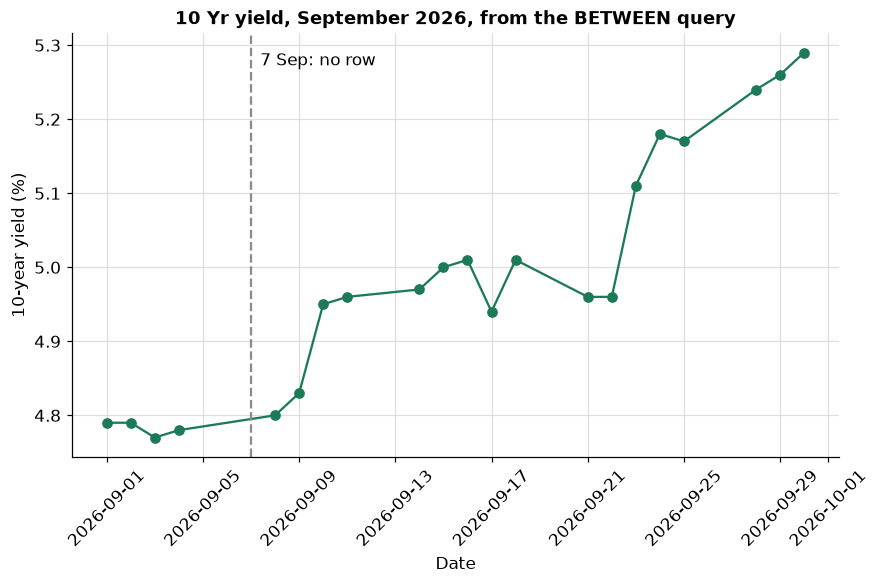

In [30]:
# the text dates from SQL become real dates, so the x axis is a true timeline
days = pd.to_datetime(sept_sql["date"])
fig, ax = plt.subplots()
ax.plot(days, sept_sql["yield_pct"], marker="o", color="#1c7a57")
# Monday 7 September has no row in the file: nothing is drawn or filled in for it
ax.axvline(pd.Timestamp("2026-09-07"), linestyle="--", color="#8c8c8c")
ax.annotate("7 Sep: no row", (pd.Timestamp("2026-09-07"), sept_sql["yield_pct"].max()), textcoords="offset points",
            xytext=(6, 0), va="top")
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Date")
ax.set_ylabel("10-year yield (%)")
ax.set_title("10 Yr yield, September 2026, from the BETWEEN query")
plt.show()

* One point for each market day the file has. The line jumps straight across 7 September, because the query returns only rows that exist.

Q. Read the result back as dates for pandas, the way the conventions table says: parse the text column.

In [31]:
# the SQL result holds text; to_datetime turns it into dates for a dated index
sept_dated = sept_sql.assign(date=pd.to_datetime(sept_sql["date"])).set_index("date")["yield_pct"]
print(f"index type: {sept_dated.index.dtype}, last value {sept_dated.iloc[-1]:.2f} percent on {sept_dated.index[-1]:%Y-%m-%d}")

index type: datetime64[us], last value 5.29 percent on 2026-09-30


Q. A month is the first seven characters of an ISO date. Summarise each month of 2026 for the 10-year yield with `substr`.

In [32]:
# substr(date, 1, 7) is YYYY-MM, the month; GROUP BY collects each month's rows
months_sql = md.run_query(DB_PATH, """
SELECT substr(date, 1, 7) AS month, COUNT(*) AS days,
       MIN(yield_pct) AS low_pct, MAX(yield_pct) AS high_pct, AVG(yield_pct) AS average_pct
FROM treasury
WHERE tenor = ? AND date >= ?
GROUP BY month
ORDER BY month
""", ("10 Yr", "2026-01-01"))

ten_2026 = curve.loc["2026":, "10 Yr"]
months_pandas = (ten_2026.groupby(ten_2026.index.strftime("%Y-%m"))
                 .agg(days="count", low_pct="min", high_pct="max", average_pct="mean")
                 .rename_axis("month").reset_index())
md.assert_same_rows(months_sql, months_pandas, sort_by=["month"])

# background_gradient shades each average by its size (Excel: Conditional Formatting, Color Scales)
(months_sql.style
    .hide(axis="index")
    .format({"low_pct": "{:.2f}", "high_pct": "{:.2f}", "average_pct": "{:.3f}"})
    .background_gradient(subset=["average_pct"], cmap="Greens")
    .set_caption("10 Yr yield by month of 2026: days, low, high, and average (percent)"))

month,days,low_pct,high_pct,average_pct
2026-01,20,4.15,4.30,4.213
2026-02,19,3.97,4.29,4.126
2026-03,22,4.05,4.44,4.246
2026-04,22,4.26,4.42,4.319
2026-05,20,4.36,4.67,4.484
2026-06,21,4.38,4.56,4.470
2026-07,22,4.48,4.75,4.600
2026-08,21,4.63,4.75,4.684
2026-09,21,4.77,5.29,4.989
2026-10,2,5.24,5.28,5.260


* 10 months, January to October. October has only the rows the file holds so far, which is why its day count is small. The averages agree to the tolerance `assert_same_rows` allows, because SQLite and pandas may add in a different order.
* `substr(date, 1, 7)` cuts the first seven characters of the text, `2026-09`, so every day of a month has the same label and `GROUP BY month` collects them. `MIN`, `MAX`, and `AVG` then summarise each group.

Q. Draw each month as a bar from its low to its high, with the average marked.

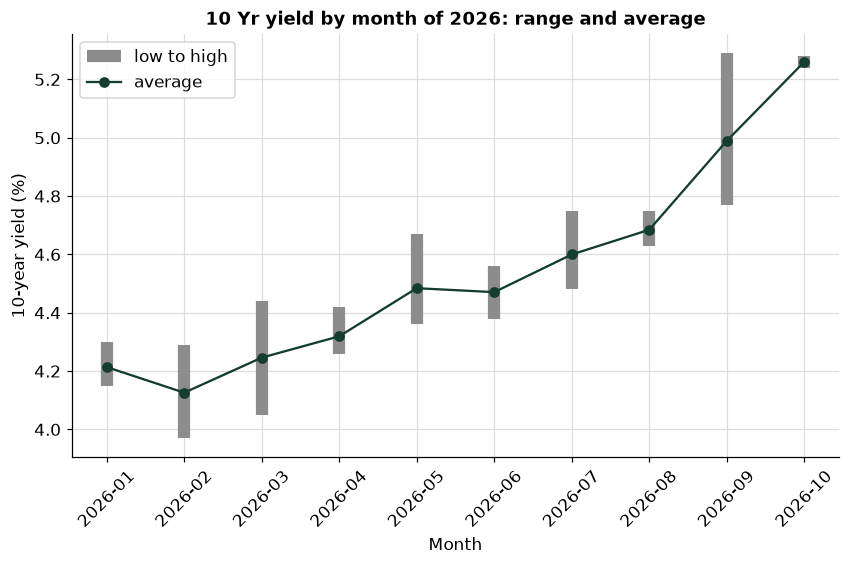

In [33]:
# a thick grey bar from the month's low to its high, and a dot at its average
fig, ax = plt.subplots()
ax.vlines(months_sql["month"], months_sql["low_pct"], months_sql["high_pct"], color="#8c8c8c", linewidth=8, label="low to high")
ax.plot(months_sql["month"], months_sql["average_pct"], marker="o", color="#123d2f", label="average")
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Month")
ax.set_ylabel("10-year yield (%)")
ax.set_title("10 Yr yield by month of 2026: range and average")
ax.legend()
plt.show()

* Each grey bar is the range the yield covered that month, and the dot is its average. October covers only the days the file holds so far.

Q. A join on a date: each September trading day's count and principal, beside the synthetic investment grade spread on that day.

In [34]:
# trade_date and the spreads' date are both ISO text, so equal text means the same day
daily_sql = md.run_query(DB_PATH, """
    SELECT t.trade_date AS date, COUNT(*) AS trades, SUM(t.principal) AS principal, s.ig_spread_bp
    FROM trades AS t
    JOIN spreads AS s ON t.trade_date = s.date
    GROUP BY t.trade_date, s.ig_spread_bp
    ORDER BY date
""")
daily_pandas = (trades.groupby("trade_date", as_index=False)
                .agg(trades=("trade_id", "count"), principal=("principal", "sum"))
                .rename(columns={"trade_date": "date"})
                .merge(spreads[["date", "ig_spread_bp"]], on="date", validate="one_to_one"))
md.assert_same_rows(daily_sql, daily_pandas, sort_by=["date"])

# every trade date found its market day: the trade count is still the blotter's
assert daily_sql["trades"].sum() == len(trades)
print(f"{len(daily_sql)} trading days, {daily_sql['trades'].sum()} trades")
daily_sql.head(3)

21 trading days, 374 trades


,date,trades,principal,ig_spread_bp
0,2026-09-01,22,7100787.00,95.0
1,2026-09-02,16,4650125.55,95.1
2,2026-09-03,16,8445714.75,94.0


* 21 days, and all 374 trades: every trade date is a market date in the spreads file. The spread column is the course's invented series, shown beside the trades as data, not as a reason for any of them.
* `JOIN spreads AS s ON t.trade_date = s.date` matches each trade to the spread row of its day. `GROUP BY` then makes one row for each day, and `COUNT` and `SUM` summarise that day's trades.

Q. Draw each trading day's principal, with the synthetic spread beneath on the same dates.

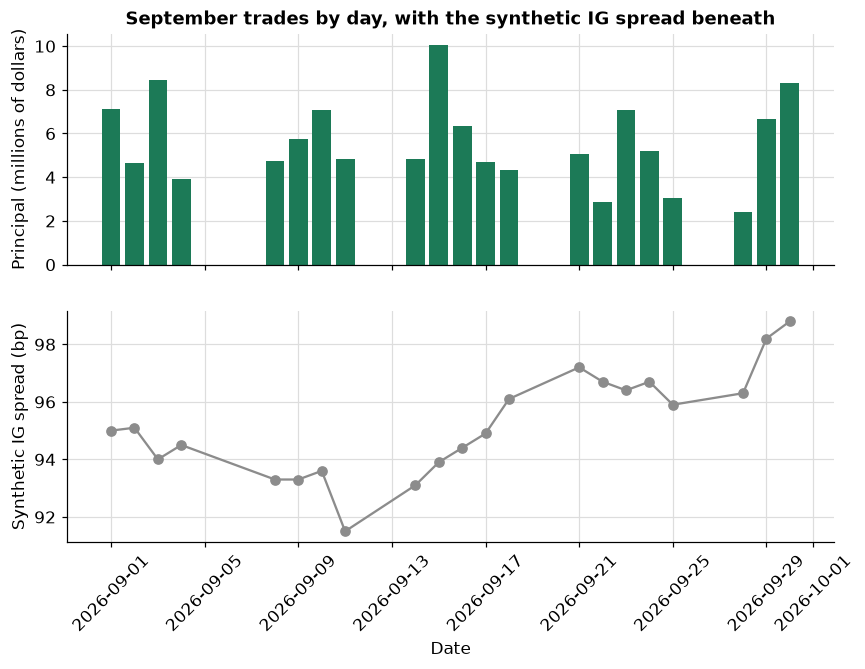

In [35]:
# two panels that share the date axis: dollars traded above, the synthetic spread below
dates = pd.to_datetime(daily_sql["date"])
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
top.bar(dates, daily_sql["principal"] / 1e6, color="#1c7a57", width=0.8)
top.set_axisbelow(True)
top.set_ylabel("Principal (millions of dollars)")
top.set_title("September trades by day, with the synthetic IG spread beneath")
bottom.plot(dates, daily_sql["ig_spread_bp"], marker="o", color="#8c8c8c")
bottom.set_ylabel("Synthetic IG spread (bp)")
bottom.set_xlabel("Date")
bottom.tick_params(axis="x", rotation=45)
plt.show()

* Above: how much principal traded each day. Below: the invented spread on the same dates. The join is what lines them up, one row for each day. The picture says nothing about why any trade happened.

## 12.5 Window Functions: LAG and ROW_NUMBER

`GROUP BY` collapses many rows into one. A **window function** keeps every row and lets each one look at its neighbours. Two do most of the work on a time series:

| Function | What each row gets | The course's function |
| --- | --- | --- |
| `LAG(x) OVER (ORDER BY date)` | the value of `x` on the previous row | `change_bp` (day 6) |
| `ROW_NUMBER() OVER (PARTITION BY month ORDER BY date DESC)` | its position in its month, counting from the last day | `last_per_period` (day 4) |

Window functions arrived in SQLite 3.25. Python's `sqlite3` module carries its own SQLite, so check the version you have.

Q. Which SQLite does this Python use?

In [36]:
import sqlite3

# the SQLite library inside this Python; window functions need 3.25 or later
print(f"SQLite {sqlite3.sqlite_version}")
assert sqlite3.sqlite_version_info >= (3, 25, 0), "this SQLite has no window functions"

SQLite 3.50.4


* SQLite 3.50.4 in the course's Python, so the window functions are there.

Q. The daily change of the 10-year yield in bp, with `LAG`.

In [37]:
# LAG(yield_pct) OVER (ORDER BY date) is the previous row's yield; times 100 turns percent into bp
change_sql = md.run_query(DB_PATH, """
SELECT date, yield_pct,
       (yield_pct - LAG(yield_pct) OVER (ORDER BY date)) * 100 AS change_bp
FROM treasury
WHERE tenor = ?
ORDER BY date
""", ("10 Yr",))

# the course's function on the same series
change = md.change_bp(curve["10 Yr"])
change_pandas = pd.DataFrame({"date": change.index.strftime("%Y-%m-%d"), "yield_pct": curve["10 Yr"].to_numpy(),
                              "change_bp": change.to_numpy()})
md.assert_same_rows(change_sql, change_pandas, sort_by=["date"])
print(f"SQL and change_bp agree on all {len(change_sql):,} rows; the first change is empty in both")
change_sql.tail(3)

SQL and change_bp agree on all 2,940 rows; the first change is empty in both


,date,yield_pct,change_bp
2937,2026-09-30,5.29,3.0
2938,2026-10-01,5.24,-5.0
2939,2026-10-02,5.28,4.0


* Each row's change is from the **previous row**, whatever the calendar gap: the conventions table's rule, the same as `change_bp`. The first row has no previous row, so its change is `NULL` in SQL and `NaN` in pandas.

Q. Now just 2026. Put the date filter inside the query, beside the tenor. What is the first change of 2026?

In [38]:
inside = md.run_query(DB_PATH, """
    SELECT date, (yield_pct - LAG(yield_pct) OVER (ORDER BY date)) * 100 AS change_bp
    FROM treasury
    WHERE tenor = ? AND date >= ?
    ORDER BY date
""", ("10 Yr", "2026-01-01"))

# the filter outside: compute the change over the whole history first, then keep 2026
outside = md.run_query(DB_PATH, """
    SELECT date, change_bp FROM (
        SELECT date, (yield_pct - LAG(yield_pct) OVER (ORDER BY date)) * 100 AS change_bp
        FROM treasury
        WHERE tenor = ?
    ) WHERE date >= ?
    ORDER BY date
""", ("10 Yr", "2026-01-01"))
print(f"filter inside:  {inside.loc[0, 'date']} change {inside.loc[0, 'change_bp']}")
print(f"filter outside: {outside.loc[0, 'date']} change {outside.loc[0, 'change_bp']:.1f} bp")
print(f"change_bp:      {change.index[change.index >= '2026-01-01'][0]:%Y-%m-%d} change {change.loc['2026'].iloc[0]:.1f} bp")

filter inside:  2026-01-02 change nan
filter outside: 2026-01-02 change 1.0 bp
change_bp:      2026-01-02 change 1.0 bp


* Inside, the first change of 2026 is missing, `nan`: `WHERE` runs **before** the window, so `LAG` never saw the last day of 2025. Outside, it is 1.0 bp, the same as `change_bp`.
* The rule: a window sees only the rows the `WHERE` leaves it. Compute the window on the whole history, then filter the result.
* `LAG(yield_pct) OVER (ORDER BY date)` means: for each row, the yield of the row before it when the rows are in date order. The subquery in brackets runs first, and the outer `WHERE date >= ?` then filters its result.

Q. Draw the first 21 daily changes of 2026, the way the filter outside the window gives them.

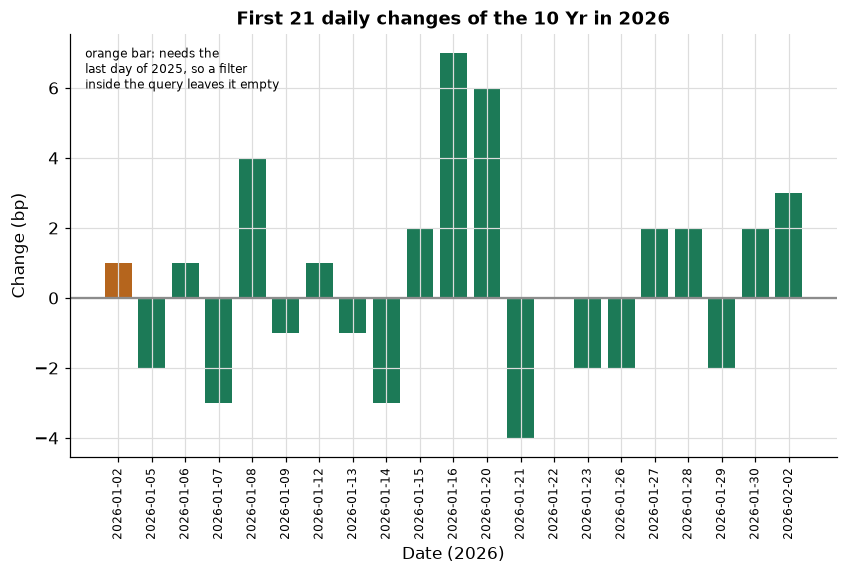

In [39]:
# the first 21 market days of 2026; the first bar is the change from the last day of 2025
first_days = outside.head(21)
fig, ax = plt.subplots()
ax.bar(first_days["date"], first_days["change_bp"], color=["#b5651d"] + ["#1c7a57"] * (len(first_days) - 1))
ax.axhline(0, color="#8c8c8c")
ax.text(0.02, 0.97, "orange bar: needs the\nlast day of 2025, so a filter\ninside the query leaves it empty", transform=ax.transAxes,
        ha="left", va="top", fontsize=8)
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.set_xlabel("Date (2026)")
ax.set_ylabel("Change (bp)")
ax.set_title("First 21 daily changes of the 10 Yr in 2026")
plt.show()

* The orange bar is the one the inside filter lost. The other bars are the same either way, because each only needs the day before it inside 2026.

Q. The last 10-year observation of each month, with `ROW_NUMBER`, against `last_per_period`.

In [40]:
# number each month's rows from the last day back; row 1 is the last observation of the month
month_end_sql = md.run_query(DB_PATH, """
SELECT date, yield_pct FROM (
    SELECT date, yield_pct,
           ROW_NUMBER() OVER (PARTITION BY substr(date, 1, 7) ORDER BY date DESC) AS row_in_month
    FROM treasury
    WHERE tenor = ?
) WHERE row_in_month = 1
ORDER BY date
""", ("10 Yr",))

month_end = md.last_per_period(curve["10 Yr"], "ME")
month_end_pandas = pd.DataFrame({"date": month_end.index.strftime("%Y-%m-%d"), "yield_pct": month_end.to_numpy()})
md.assert_same_rows(month_end_sql, month_end_pandas, sort_by=["date"])
print(f"{len(month_end_sql)} months, each labelled by the date of its last observation")
month_end_sql.tail(3)

142 months, each labelled by the date of its last observation


,date,yield_pct
139,2026-08-31,4.75
140,2026-09-30,5.29
141,2026-10-02,5.28


* 142 months, and every one equals `last_per_period`. September 2026 is labelled 2026-09-30, 5.29 percent, because that row exists. The last row is 2026-10-02, 5.28 percent: October is not over, so its last observation so far is the file's last row.
* `PARTITION BY substr(date, 1, 7)` restarts the numbering each month, and `ORDER BY date DESC` counts from the end, so the label is always a date the market had. This is the course's convention, and the reason `resample("ME").last()` was not used: it labels each month by the calendar month end.
* `ROW_NUMBER() OVER (PARTITION BY ... ORDER BY date DESC)` numbers the rows inside each month, newest first. The subquery in brackets adds that number, and the outer `WHERE row_in_month = 1` keeps only the newest row of each month.

Q. Draw the 2026 daily yield with each month's last observation marked.

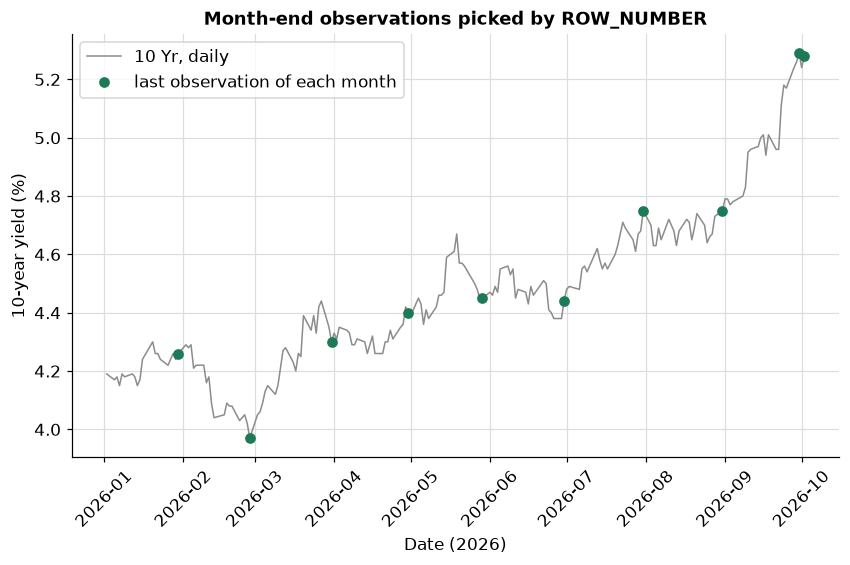

In [41]:
# the daily 10 Yr in grey, and a green dot on the row ROW_NUMBER picked for each month
daily = curve.loc["2026", "10 Yr"]
ends = month_end_sql.assign(date=pd.to_datetime(month_end_sql["date"]))
ends = ends[ends["date"] >= "2026-01-01"]
fig, ax = plt.subplots()
ax.plot(daily.index, daily.to_numpy(), color="#8c8c8c", linewidth=1, label="10 Yr, daily")
ax.plot(ends["date"], ends["yield_pct"], marker="o", linestyle="none", color="#1c7a57", label="last observation of each month")
ax.set_xlabel("Date (2026)")
ax.set_ylabel("10-year yield (%)")
ax.tick_params(axis="x", rotation=45)
ax.set_title("Month-end observations picked by ROW_NUMBER")
ax.legend()
plt.show()

* Each dot sits on the grey line at the last date the market had in its month. Two sentences of SQL replaced a loop over the months.

## The Two Tests

Q. Add today's two tests: the trades-to-holdings join on cusip keeps all 374 trades and the blotter's principal, and the month ends from SQL equal `last_per_period`. Read them before you run the cell.

In [42]:
%%writefile -a test_marketdata.py


def test_trades_join_holdings_on_cusip_keeps_rows(tmp_path):
    db_path = tmp_path / "course3.db"
    md.load_tables(db_path, {"trades": HERE / "trade_blotter.csv", "holdings": HERE / "holdings.csv"})
    joined = md.run_query(db_path, "SELECT t.trade_id, t.cusip, t.principal, h.sector FROM trades AS t "
                                   "JOIN holdings AS h ON t.cusip = h.cusip")
    # cusip is unique in holdings, so every trade appears once
    assert len(joined) == 374
    assert round(joined["principal"].sum(), 2) == 117_473_749.35
    # the same join in pandas, with validate= stopping on a key that repeats on the right
    trades, holdings = pd.read_csv(HERE / "trade_blotter.csv"), pd.read_csv(HERE / "holdings.csv")
    merged = trades.merge(holdings[["cusip", "sector"]], on="cusip", validate="many_to_one")
    md.assert_same_rows(joined, merged[["trade_id", "cusip", "principal", "sector"]], sort_by=["trade_id"])


def test_month_end_sql_matches_last_per_period(tmp_path):
    # the Treasury file in long form: one row per date and tenor, missing tenors dropped, dates as ISO text
    curve = read_treasury()
    long = curve.reset_index().melt(id_vars="date", var_name="tenor", value_name="yield_pct").dropna()
    long["date"] = long["date"].dt.strftime("%Y-%m-%d")
    long.to_csv(tmp_path / "treasury_long.csv", index=False)
    db_path = tmp_path / "course3.db"
    md.load_tables(db_path, {"treasury": tmp_path / "treasury_long.csv"})
    sql = """
        SELECT date, yield_pct FROM (
            SELECT date, yield_pct,
                   ROW_NUMBER() OVER (PARTITION BY substr(date, 1, 7) ORDER BY date DESC) AS row_in_month
            FROM treasury WHERE tenor = ?
        ) WHERE row_in_month = 1
    """
    month_end_sql = md.run_query(db_path, sql, ("10 Yr",))
    month_end = md.last_per_period(curve["10 Yr"], "ME")
    expected = pd.DataFrame({"date": month_end.index.strftime("%Y-%m-%d"), "yield_pct": month_end.to_numpy()})
    md.assert_same_rows(month_end_sql, expected, sort_by=["date"])
    assert len(month_end_sql) == 142

Appending to test_marketdata.py


* The first test makes the join in SQL and in pandas, and pandas' `validate="many_to_one"` would stop it if cusip ever repeated in holdings.
* The second builds the long Treasury table in its own `tmp_path` folder, so it never touches the notebook's database.

Q. Run the tests.

In [43]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................................................                         [100%]
48 passed in 1.50s



* `48 passed`: yesterday's 46 and today's two.

## Excel Side by Side

Excel joins tables too: one column at a time with `XLOOKUP`, or whole tables with Power Query's Merge. Every line below was tested in Excel (Excel 16.0 build 20430, 2026-10-04) on the course's files.

| Job | SQL | pandas | Excel (tested) | Excel returns |
| --- | --- | --- | --- | --- |
| Each trade's sector from holdings by cusip | `JOIN holdings AS h ON t.cusip = h.cusip` | `merge(..., on="cusip")` | `=XLOOKUP(F2,$A$2:$A$201,$C$2:$C$201)`, filled down over the 374 trades | 0 `#N/A`; the same sector as pandas on every row |
| The same lookup by ticker, a key that repeats | `JOIN ... ON t.ticker = h.ticker` adds rows | `MergeError` with `validate=` | `=XLOOKUP(G2,$B$2:$B$201,$A$2:$A$201)`, filled down | the first bond of each issuer: 178 of the 374 trades get a cusip that is not the bond they traded |
| Find keys that repeat | `GROUP BY ticker HAVING COUNT(*) > 1` | `value_counts()` | `=COUNTIF($B$2:$B$201,B2)`, filled down over holdings | 145 rows above 1, 60 tickers, largest 6; on the cusip column, largest 1 |
| Principal by side | `SUM(principal) ... GROUP BY side` | `groupby("side")` | `=SUMIFS($I$2:$I$375,$H$2:$H$375,"BUY")` | 56,556,005.45 dollars for BUY |
| A whole-table join | `LEFT JOIN holdings ... ON cusip` | `merge(how="left")` | Power Query Merge, `Table.NestedJoin(Trades, {"cusip"}, Holdings, {"cusip"}, "r", JoinKind.LeftOuter)` | 374 rows |
| Holdings with the benchmark on ticker | the duplicate trap | the duplicate trap | `Table.NestedJoin(Holdings, {"ticker"}, Benchmark, {"ticker"}, "r", JoinKind.LeftOuter)` | 1,213 rows from 200; on cusip, 200 |
| Rows with no match | `LEFT JOIN ... WHERE h.cusip IS NULL` | `indicator=True`, `left_only` | `Table.NestedJoin(Benchmark, {"cusip"}, Holdings, {"cusip"}, "h", JoinKind.LeftAnti)` | 621 rows |
| The last observation of each month | `ROW_NUMBER() OVER (PARTITION BY ...)` | `last_per_period(..., "ME")` | `=MAXIFS($A$2:$A$2941,$A$2:$A$2941,"<="&EOMONTH(D2,0))` for the date, then `=XLOOKUP(E2,$A$2:$A$2941,$B$2:$B$2941)` | the last row of each month, on all 12 months of 2025 tested |
| The daily change in bp | `LAG(...) OVER (ORDER BY date)` | `change_bp` | `=(B3-B2)*100`, filled down | equal to the Python arithmetic exactly (tested for the course's reference file) |

**`XLOOKUP` as a join.** Put the holdings' cusip, ticker, and sector in columns A to C, and the trades beside them. In the first trade's row write `XLOOKUP` of the trade's cusip in the holdings' cusip column, returning the sector column, and fill it down. That is a many-to-one join, one column at a time. No `#N/A` came back, which is Excel's way of saying every trade found its bond.

**A repeated key, the Excel way.** `XLOOKUP` returns the **first** match and stops. So looking a trade up by ticker never adds rows, as the SQL join does; it quietly picks the issuer's first bond in the list. The test found 178 of the 374 trades given a bond they did not trade. A different symptom from the same cause: a key that repeats.

**`COUNTIF` finds the repeats.** `COUNTIF` of each ticker over the whole ticker column, filled down, counts how often each row's key appears. Anything above 1 repeats. On the cusip column the largest count is 1, which is what makes cusip a key.

**Power Query Merge.** Data, Get Data, From File, From Text/CSV for each file, then Home, Merge Queries: pick the key column in each table and a join kind, then expand the columns you want. Trades with holdings, Left Outer on cusip, returned 374 rows, one per trade. Holdings with the benchmark on ticker returned 1,213 rows from 200, the same duplicate trap as section 12.3; on cusip, 200. Left Anti on cusip, benchmark against holdings, returned the 621 benchmark bonds the book does not hold, the same rows as the `LEFT JOIN ... IS NULL` above.

**Month ends.** `MAXIFS` of the date column, for dates at or before `EOMONTH` of a day in the month, gives the month's last market date; `XLOOKUP` of that date gives the value. Equal to the last row of each month on every month tested. The exercises do the same in SQL for 2025.

Q. Do the pandas lookups give Excel's numbers?

In [44]:
# Excel's XLOOKUP by ticker returns the first holding of each ticker: drop_duplicates keeps the first
first_bond = holdings.drop_duplicates("ticker").set_index("ticker")["cusip"]
print(f"trades given another bond by a first-match lookup on ticker: {(trades['ticker'].map(first_bond) != trades['cusip']).sum()}")
print(f"BUY principal: {trades.loc[trades['side'] == 'BUY', 'principal'].sum():,.2f} dollars")

trades given another bond by a first-match lookup on ticker: 178
BUY principal: 56,556,005.45 dollars


* 178 and 56,556,005.45: the same as Excel.

## Save the Day with Git

Today's Git step reads history one file at a time. Commit the module and the tests, then `queries.sql` twice, and ask Git which commits touched `queries.sql`.

Q. Make the work folder a repository.

In [45]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [46]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course3_12_lhiriy_4 and nowhere else


Q. Write `.gitignore`, so the database never goes in, and commit the module, the tests, and `.gitignore`.

In [47]:
%%writefile .gitignore
# databases and folders Python and pytest make: rebuilt, never part of the record
*.db
__pycache__/
.pytest_cache/

Writing .gitignore


In [48]:
# commit the three files; the database shows as ignored, !!
!git -C "{work}" add .gitignore marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Add the day 12 tests: trades join holdings on cusip, month ends in SQL"
!git -C "{work}" status --short --ignored course3.db

!! course3.db


Q. Write `queries.sql` with the day's joins, and commit it.

In [49]:
%%writefile queries.sql
-- queries.sql: the day's queries, run with ? parameters from Python (marketdata.run_query)

-- every holding with its issuer and its rating's bucket and grade (many to one, twice)
SELECT h.cusip, h.ticker, i.issuer, i.country, h.rating, r.bucket, r.grade, h.market_value
FROM holdings AS h
JOIN issuers AS i ON h.ticker = i.ticker
JOIN ratings AS r ON h.rating = r.rating;

-- trades and principal by grade: trades to holdings on cusip, then to ratings
SELECT r.grade, COUNT(*) AS trades, SUM(t.principal) AS principal
FROM trades AS t
JOIN holdings AS h ON t.cusip = h.cusip
JOIN ratings AS r ON h.rating = r.rating
GROUP BY r.grade
ORDER BY r.grade;

-- benchmark bonds the book does not hold
SELECT b.cusip, b.ticker, b.sector, b.weight_pct
FROM benchmark AS b
LEFT JOIN holdings AS h ON b.cusip = h.cusip
WHERE h.cusip IS NULL;

-- keys that repeat: a ticker with more than one bond in the benchmark
SELECT ticker, COUNT(*) AS bonds
FROM benchmark
GROUP BY ticker
HAVING COUNT(*) > 1
ORDER BY bonds DESC, ticker;

Writing queries.sql


In [50]:
!git -C "{work}" add queries.sql
!git -C "{work}" commit -q -m "Add queries.sql with the day's joins"

Q. Add the time series queries to `queries.sql`, and commit again.

In [51]:
%%writefile -a queries.sql


-- one tenor between two dates; dates are ISO text, and BETWEEN includes both ends
SELECT date, yield_pct
FROM treasury
WHERE tenor = ? AND date BETWEEN ? AND ?
ORDER BY date;

-- the daily change in bp, from the previous row of the same tenor
SELECT date, yield_pct,
       (yield_pct - LAG(yield_pct) OVER (ORDER BY date)) * 100 AS change_bp
FROM treasury
WHERE tenor = ?
ORDER BY date;

-- the last observation of each month, labelled by its own date
SELECT date, yield_pct FROM (
    SELECT date, yield_pct,
           ROW_NUMBER() OVER (PARTITION BY substr(date, 1, 7) ORDER BY date DESC) AS row_in_month
    FROM treasury
    WHERE tenor = ?
) WHERE row_in_month = 1
ORDER BY date;

Appending to queries.sql


In [52]:
!git -C "{work}" add queries.sql
!git -C "{work}" commit -q -m "Add the time series queries to queries.sql"

Q. Which commits touched `queries.sql`, and what did the last one change?

In [53]:
# the whole history, then only the commits that touched queries.sql
!git -C "{work}" log --oneline
!git -C "{work}" log --oneline -- queries.sql

a53f903 Add the time series queries to queries.sql
abd9ad1 Add queries.sql with the day's joins
5d6d09c Add the day 12 tests: trades join holdings on cusip, month ends in SQL


a53f903 Add the time series queries to queries.sql
abd9ad1 Add queries.sql with the day's joins


In [54]:
# the last commit: its message, and the files it changed with a count of lines
!git -C "{work}" show HEAD --stat

commit a53f903a6b37abd401e9484505ed56fbe33e4ee0
Author: Course Student <student@example.com>
Date:   Mon Oct 19 00:50:09 2026 -0400

    Add the time series queries to queries.sql

 queries.sql | 23 +++++++++++++++++++++++
 1 file changed, 23 insertions(+)


* `git log --oneline` lists three commits. With `-- queries.sql` at the end, only the two that touched that file. The `--` separates options from file names.
* `git show HEAD --stat` shows the last commit's message and one line per file changed: `queries.sql`, with the number of lines added. When you wonder when a query changed, these two commands answer it.

## Bring It Home

Today adds no function, only two tests. Add them to `test_marketdata.py` in your `my_bondmath` folder. Open a PowerShell terminal in VS Code, with the course's `.venv` active.

**Step 1.** The new tests read three data files from the folder of the test file. `holdings.csv` has been there since day 11 and `treasury_par_yields.csv` since day 4; copy the third, the trade blotter, from the course repo's `data` folder.

```powershell
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$HOME\projects\python-fixed-income\data\trade_blotter.csv" .
```

**Step 2.** Open the test file and paste the code of the `%%writefile -a test_marketdata.py` cell of "The Two Tests", without its first line, at the end. Save it.

```powershell
code test_marketdata.py
```

**Step 3.** Run the tests, read the change, and commit.

```powershell
python -m pytest -q test_marketdata.py
git diff --stat
git add test_marketdata.py
git commit -m "Add the day 12 tests: trades join holdings on cusip, month ends in SQL"
```

The last line of pytest says `48 passed`. `*.db` has been in your `.gitignore` since day 1, so a database made in this folder stays out of Git.

**In Colab**, download `test_marketdata.py` and `queries.sql` from the work folder under `/tmp` in the file browser.

## You Can Now

* Join two or three tables in SQL with `JOIN ... ON`, and write the same join in pandas with `merge` and `validate=`.
* Find the rows that do not match with `LEFT JOIN ... WHERE ... IS NULL`, and with `indicator=True` in pandas.
* Count before and after every join, compare a control total, and name the key that repeats with `GROUP BY ... HAVING`.
* Store dates as ISO text, select with `BETWEEN`, and group by month with `substr(date, 1, 7)`.
* Use `LAG` for a change in bp and `ROW_NUMBER` for the last observation of each month, and filter after the window, not before.
* Prove every query against pandas with `assert_same_rows`.

Tomorrow, day 13, is the second pass at working with an AI assistant: the prompt as a spec, reviewing the pandas, chart, and bond code an assistant writes, what never to paste into a chat, and a package that does not exist.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell. Every SQL answer gets a pandas twin and an `assert_same_rows`.

Q. Run the next cell first. It builds the exercises' database from the trades, the holdings, and the Treasury file in long form, reads the same files into pandas, and defines `check`, a small function that marks your answers.

In [55]:
# the exercises' own database, so they run without the lesson
DB_PATH = work / "course3.db"
DB_PATH.unlink(missing_ok=True)
trades = pd.read_csv("trade_blotter.csv")
holdings = pd.read_csv("holdings.csv")
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date")
# the Treasury file in long form, dates as ISO text
long = curve.reset_index().melt(id_vars="date", var_name="tenor", value_name="yield_pct").dropna()
long["date"] = long["date"].dt.strftime("%Y-%m-%d")
long.to_csv("treasury_long.csv", index=False)
counts = md.load_tables(DB_PATH, {"trades": work / "trade_blotter.csv", "holdings": work / "holdings.csv",
                                  "treasury": work / "treasury_long.csv"})
print(counts)


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

{'trades': 374, 'holdings': 200, 'treasury': 35728}


### Exercise 1

Q. Traded principal by sector and side: join trades to holdings on cusip and add up `principal` for each `sector` and `side`, in SQL, with the columns `sector`, `side`, `principal`. Write the pandas twin and compare them with `md.assert_same_rows`. Store the number of rows in **ex1_rows** and the principal of Energy buys, in dollars, in **ex1_energy_buy**.

In [56]:
ex1_rows = ...
ex1_energy_buy = ...

In [57]:
check("Exercise 1 sector and side pairs", ex1_rows, 20)
check("Exercise 1 Energy buys", ex1_energy_buy, 9290328.45)

Exercise 1 sector and side pairs: not attempted yet
Exercise 1 Energy buys: not attempted yet


### Exercise 2

Q. The last 10-year observation of each month of 2025, in SQL, with `ROW_NUMBER`: columns `date` and `yield_pct`. Compare it with `md.last_per_period` on the 2025 rows of `curve["10 Yr"]`. Store the number of rows in **ex2_rows**, September's date (ISO text) in **ex2_september_date**, and its yield in percent in **ex2_september_pct**.

In [58]:
ex2_rows = ...
ex2_september_date = ...
ex2_september_pct = ...

In [59]:
check("Exercise 2 months", ex2_rows, 12)
check("Exercise 2 September date", ex2_september_date, '2025-09-30')
check("Exercise 2 September yield", ex2_september_pct, 4.16)

Exercise 2 months: not attempted yet
Exercise 2 September date: not attempted yet
Exercise 2 September yield: not attempted yet


### Exercise 3

Q. Add a function to your module. `join_row_check(left, right, on)` left-joins `right` onto `left` on one key column, returns the joined table, and raises `ValueError` if the join changed the number of rows of `left`, naming both counts. Write the docstring first. Then add a test, `test_join_row_check_keeps_rows_and_stops_on_a_repeated_key`, that checks trades joined to holdings' `cusip` and `sector` keeps 374 rows, and that joining on `ticker` raises. Run pytest, reload the module, and store `len(md.join_row_check(trades, holdings[["cusip", "sector"]], on="cusip"))` in **ex3_rows**, and `True` in **ex3_stops** if joining on `ticker` raises `ValueError`.

Write the function in the cell that starts with `%%writefile -a marketdata.py` and the test in the one that starts with `%%writefile -a test_marketdata.py`, and run each of those cells once.

In [60]:
%%writefile -a marketdata.py


# Exercise 3: write join_row_check(left, right, on) below this line

Appending to marketdata.py


In [61]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_join_row_check_keeps_rows_and_stops_on_a_repeated_key() below this line

Appending to test_marketdata.py


In [62]:
# run pytest, reload the module, then call your function
ex3_rows = ...
ex3_stops = ...

In [63]:
check("Exercise 3 rows kept on cusip", ex3_rows, 374)
check("Exercise 3 stops on ticker", ex3_stops, True)

Exercise 3 rows kept on cusip: not attempted yet
Exercise 3 stops on ticker: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a function that gives every September trade the sector of the bond traded, and you give it the docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Every trade of the blotter with the sector of the bond traded, one row per trade.

    Units: principal in dollars, as the blotter has it. Convention: exactly one row for each trade in the
    trades table, so the principal column sums to the blotter's total; the sector comes from holdings.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, it returns a table with the right columns, and it contains one bug.

In [64]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def trades_with_sector(db_path):
    """Every trade of the blotter with the sector of the bond traded, one row per trade.

    Units: principal in dollars, as the blotter has it. Convention: exactly one row for each trade in the
    trades table, so the principal column sums to the blotter's total; the sector comes from holdings.
    """
    # ticker is in both tables, so join on it
    sql = """
        SELECT t.trade_id, t.trade_date, t.side, t.principal, h.sector
        FROM trades AS t
        JOIN holdings AS h ON t.ticker = h.ticker
    """
    return md.run_query(db_path, sql)

Q. Predict before you run anything: the blotter has 374 trades. How many rows will `trades_with_sector(DB_PATH)` return? Read the `ON` line.

Q. Test the function against its docstring before you trust it: one row per trade, and the blotter's principal.

In [65]:
# the test, written from the docstring before the code is trusted
result = trades_with_sector(DB_PATH)
print(f"{len(result)} rows, principal {result['principal'].sum():,.2f} dollars")
assert len(result) == len(trades), f"{len(result)} rows for {len(trades)} trades"
assert round(result["principal"].sum(), 2) == round(trades["principal"].sum(), 2), "principal differs from the blotter"
print("One row per trade, and the blotter's principal")

831 rows, principal 252,709,336.05 dollars


AssertionError: 831 rows for 374 trades

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the number of rows the fixed function returns in **ex4_rows**, and its principal total, rounded to cents, in **ex4_principal**.

In [66]:
# fix the function above and run the test again, then store the two answers
ex4_rows = ...
ex4_principal = ...

In [67]:
check("Exercise 4 one row per trade", ex4_rows, 374)
check("Exercise 4 the blotter's principal", ex4_principal, 117473749.35)

Exercise 4 one row per trade: not attempted yet
Exercise 4 the blotter's principal: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```